# Detección de vehículos con YOLO · Evaluación 03
### Machine Learning · Universidad Bernardo O'Higgins · Dr. Eliecer Peña Ancavil

**Integrantes:**
- Ignacio Ibañez
- Gerardo Gonzalez
- Deyner Angulo

**Tema:** un detector de objetos que encuentra **autos (`Car`), camiones (`Truck`) y buses (`Bus`)** en fotografías y en video.

**Dataset:** Vehicles-OpenImages, versión 1 (416×416), Roboflow Universe, autor Jacob Solawetz, licencia **CC BY 4.0**.
Enlace: https://universe.roboflow.com/roboflow-gw7yv/vehicles-openimages/dataset/1
El dataset trae 5 clases (Ambulance, Bus, Car, Motorcycle, Truck); nos quedamos con 3.

**Base del código:** plantilla *ML Clase10 Caras YOLO.ipynb* del Dr. Eliecer Peña Ancavil. Las funciones auxiliares (Parte 1) se usan sin cambios. Lo que cambiamos respecto de la plantilla está marcado con **[Detección de vehículos con YOLO]**.

**Recorrido**

- Parte 0 · Preparar Google Colab y su GPU.
- Parte 1 · Funciones auxiliares (de la plantilla, sin cambios).
- Parte 2 · YOLO tal como viene.
- Parte 3 · El dataset: descarga, limpieza de duplicados, filtrado de clases y conteos.
- Parte 4 · Transfer learning.
- Parte 5 · ¿Cómo se mide un detector?
- Parte 6 · Fine tuning.
- Parte 7 · Comparar los modelos con Validation y elegir.
- Parte 8 · Evaluación final con Test y análisis de errores.
- Parte 9 · Usar el modelo con imágenes y con video.
- Parte 10 · Guardar el modelo y los resultados.


---
# Parte 0 · Preparar Google Colab y su GPU

## Activar la GPU

`Entorno de ejecución` → `Cambiar tipo de entorno de ejecución` → **T4 GPU** → `Guardar`.

Esto reinicia la sesión. Si no consigues GPU, el notebook funciona en CPU, pero **entrenar sin GPU tarda horas**: en ese caso, prueba más tarde.

## Lo que hay que saber de Colab gratis

- La GPU **no está garantizada**: Google la asigna según disponibilidad.
- Una sesión dura **como máximo 5 horas**, y se corta antes si la dejas inactiva.
- Si la sesión se corta, **se pierde todo lo que está en `/content`**. Por eso la Parte 10 arma un ZIP con el modelo para descargarlo.
- Nuestro dataset es chico (439 imágenes de Train), así que con la configuración de abajo el notebook completo debería tomar **unos 20 a 40 minutos** en la T4 (estimación; el tiempo real queda medido en las Partes 4A y 6A).

## Instalación

Colab no trae Ultralytics (la librería de YOLO) ni `kagglehub` (para bajar el dataset). La celda siguiente los instala. No hace falta reiniciar la sesión.

In [1]:
# ============================================================
# PARTE 0A · Instalación (Colab no trae Ultralytics)
# ============================================================
%pip install -q ultralytics kagglehub

In [2]:
# ============================================================
# PARTE 0B · Librerías, semilla y detección de GPU
# ============================================================
import os
import json
import time
import shutil
import random
import zipfile
import getpass
import warnings
import urllib.request
from pathlib import Path

import cv2
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import ultralytics
from ultralytics import YOLO
from PIL import Image, ImageDraw, ImageFont
from matplotlib.ticker import MaxNLocator

warnings.filterwarnings("ignore")

SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# 0 = primera GPU; si no hay GPU, se usa la CPU
DISPOSITIVO = 0 if torch.cuda.is_available() else "cpu"
NOMBRE_GPU = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "sin GPU"

print("Ultralytics:", ultralytics.__version__, "| PyTorch:", torch.__version__)
print("Dispositivo:", NOMBRE_GPU)
if DISPOSITIVO == "cpu":
    print("ATENCIÓN: no hay GPU. El entrenamiento tardará horas.")

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.203 | PyTorch: 2.14.1+cu130
Dispositivo: Tesla T4


## Configuración general: aquí se modifican los hiperparámetros

Todo lo que se puede cambiar está en esta celda. Las carpetas se crean **en la misma carpeta del notebook** (en Colab, `/content`).

**[Detección de vehículos con YOLO] Decisiones y por qué:**

- `dataset_zip` y `drive_id`: el ZIP de Roboflow (formato YOLO26). Si no está junto al notebook, la Parte 3A lo baja de nuestro Google Drive con su id, así el notebook corre desde un entorno limpio sin subir nada a mano.
- `clases`: `["Car", "Truck", "Bus"]`, escritas **igual que en el `data.yaml`** (con mayúscula). El orden define los nuevos números: Car = 0, Truck = 1, Bus = 2.
- `imgsz = 416`: Roboflow ya entrega las imágenes a 416×416 (preprocesado *Resize: Stretch*). Usar 640 solo agrandaría píxeles que no existen y entrenaría más lento.
- `fraccion_transfer` y `fraccion_fine_tuning = 1.0`: el Train tiene solo 439 imágenes, así que usamos todas (el enunciado lo permite si el dataset es chico).
- Épocas (30 y 20) y `paciencia = 10`: con pocas imágenes, cada época es corta, así que podemos entrenar más que la referencia de caras (8 y 5). La paciencia corta el entrenamiento si Validation deja de mejorar, para no sobreajustar. En la corrida de prueba, con paciencia 10, los dos entrenamientos se cortaron en la época 11 mientras el mAP de Validation todavía se estaba recuperando; la subimos a 20.
- `fraccion_test` no se usa: la versión ya trae Train, Validation y Test, y los conservamos.


In [3]:
# ============================================================
# CONFIGURACIÓN EDITABLE · Un único lugar para hacer cambios
# ============================================================
PARAMETROS = {
    "modelo_base": "yolo26n.pt",      # YOLO26 nano: el más liviano; ya detecta 80 tipos de objetos
    "dataset_kaggle": None,            # [Proyecto] no se usa: el dataset viene de Roboflow
    "dataset_zip": "Vehicles-OpenImages.v1-416x416.yolo26.zip",   # [Proyecto] ZIP de Roboflow (YOLO26)
    "drive_id": "1IXm0Kp_fM0Of_XMeQsPIXvQZnNwc3Tdm",           # [Proyecto] id del ZIP en Google Drive (respaldo)
    "drive_ejemplos": "1O4vvIjejutVOr-nuSOLaWi6Lv1wCcW18",     # [Proyecto] carpeta de Drive con nuestras fotos y videos
    "clases": ["Car", "Truck", "Bus"],  # [Proyecto] 3 de las 5 clases, con los nombres exactos del data.yaml
    "fraccion_test": 0.15,            # no se usa: la versión ya trae train, valid y test
    "imgsz": 416,                     # lado (en píxeles) al que YOLO redimensiona cada imagen
    "batch": -1,                      # -1 = Ultralytics elige el lote según la memoria de la GPU
    "workers": 2,                     # procesos que cargan imágenes (Colab gratis tiene 2 núcleos)
    "epocas_transfer": 30,            # [Proyecto] dataset chico: épocas cortas, podemos entrenar más
    "fraccion_transfer": 1.0,         # [Proyecto] Train completo (439 imágenes)
    "capas_congeladas": 10,           # se congelan las 10 primeras capas (el backbone)
    "epocas_fine_tuning": 20,         # [Proyecto]
    "fraccion_fine_tuning": 1.0,      # [Proyecto] Train completo
    "lr_fine_tuning": 1e-4,           # [Proyecto] 5e-4 hizo caer el mAP50-95 de Validation de 0,43 a 0,07
    "paciencia": 20,                  # [Proyecto] 10 cortaba el entrenamiento mientras Validation se recuperaba
    "confianza": 0.25,                # confianza mínima para dibujar una caja
    "cache": "disk",                  # guarda las imágenes preprocesadas en disco: entrena más rápido
    "horas_maximas_transfer": None,   # opcional: tope de horas (si se usa, reemplaza a las épocas)
    "horas_maximas_fine_tuning": None,
}

In [4]:
# ============================================================
# CONFIGURACIÓN · Carpetas (todas junto al notebook)
# ============================================================
BASE = Path.cwd()                                  # carpeta del notebook (en Colab: /content)
DATOS = BASE / ("datos_proyecto" if PARAMETROS["dataset_zip"] else "datos_caras")  # Train / Validation / Test
RUNS = BASE / "runs_c10"                 # lo que guarda Ultralytics en cada entrenamiento
RESULTADOS = BASE / "resultados_c10"     # modelos, figuras y cifras para llevarse
FIGURAS = RESULTADOS / "figuras"
for carpeta in (RUNS, FIGURAS):
    carpeta.mkdir(parents=True, exist_ok=True)

NOMBRES = {}                # [Proyecto] se leen del data.yaml del ZIP en la Parte 3B
NUMEROS = {"parametros": PARAMETROS, "dispositivo": NOMBRE_GPU,
           "ultralytics": ultralytics.__version__}   # cifras que se guardan al final

print("Carpeta de trabajo:", BASE)
print(pd.Series(PARAMETROS, name="Valor").to_string())

Carpeta de trabajo: /content
modelo_base                                                 yolo26n.pt
dataset_kaggle                                                    None
dataset_zip                  Vehicles-OpenImages.v1-416x416.yolo26.zip
drive_id                             1IXm0Kp_fM0Of_XMeQsPIXvQZnNwc3Tdm
drive_ejemplos                       1O4vvIjejutVOr-nuSOLaWi6Lv1wCcW18
clases                                               [Car, Truck, Bus]
fraccion_test                                                     0.15
imgsz                                                              416
batch                                                               -1
workers                                                              2
epocas_transfer                                                     30
fraccion_transfer                                                  1.0
capas_congeladas                                                    10
epocas_fine_tuning                              

---
# Parte 1 · Funciones auxiliares

**No necesitas leer este código para seguir la clase, pero sí ejecutar sus cuatro celdas**: el resto del notebook las usa. Están aquí para que el resto del notebook quede limpio.

In [5]:
# ============================================================
# PARTE 1A · Estilo de los gráficos y guardado
# ============================================================
TRAIN, VALID, TEST = "#4C72B0", "#DD8452", "#C44E52"   # colores fijos del curso
MEJOR, RESTO = "#1F8A70", "#B8C7D9"
TAMANO = {"completa": (13.0, 6.2), "mitad": (6.6, 5.0)}



def estilo():
    '''Estilo del curso. Se vuelve a aplicar en cada gráfico porque Ultralytics cambia el de matplotlib.'''
    sns.set_theme(style="whitegrid", context="talk")
    plt.rcParams.update({"axes.titleweight": "bold", "axes.titlesize": 20, "axes.labelsize": 16,
                         "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 13,
                         "figure.dpi": 100, "savefig.dpi": 200, "font.family": "sans-serif",
                         "font.sans-serif": ["DejaVu Sans"]})


estilo()


def guardar_figura(nombre):
    '''Guarda la figura activa en figuras/ (recortada) y la muestra.'''
    ruta = FIGURAS / nombre
    plt.savefig(ruta, dpi=200, bbox_inches="tight", pad_inches=0.05, facecolor="white")
    plt.show()
    print("Gráfico guardado:", ruta.name)


def copiar_figura(origen, nombre, titulo=None):
    '''Copia a figuras/ un gráfico que generó Ultralytics y lo muestra.'''
    estilo()
    origen = Path(origen)
    if not origen.exists():
        print("No se encontró", origen.name)
        return
    img = Image.open(origen)
    alto = 13.0 * img.height / img.width
    plt.figure(figsize=(13.0, alto))
    plt.imshow(img)
    plt.axis("off")
    if titulo:
        plt.title(titulo)
    guardar_figura(nombre)


def cargar_imagen(ruta):
    '''Abre una imagen como RGB.'''
    return Image.open(ruta).convert("RGB")


def grilla(n, columnas=3, alto_fila=3.1):
    '''Figura con n paneles en filas de `columnas`; los sobrantes quedan en blanco.'''
    filas = int(np.ceil(n / columnas))
    columnas = min(columnas, n)
    fig, ejes = plt.subplots(filas, columnas, figsize=(13.0, alto_fila * filas + 0.6))
    ejes = np.atleast_1d(ejes).ravel()
    for ax in ejes[n:]:
        ax.axis("off")
    return fig, ejes[:n]

In [6]:
# ============================================================
# PARTE 1B · El dataset: carpetas, etiquetas YOLO y YAML
# ============================================================
EXTENSIONES = {".jpg", ".jpeg", ".png", ".webp", ".bmp"}


def listar_imagenes(carpeta):
    '''Imágenes de una carpeta, ordenadas por nombre.'''
    carpeta = Path(carpeta)
    if not carpeta.exists():
        return []
    return sorted(p for p in carpeta.iterdir() if p.suffix.lower() in EXTENSIONES)


def buscar_split(raiz, split):
    '''Busca un split en las dos estructuras habituales:
    images/train + labels/train   o   train/images + train/labels.'''
    raiz = Path(raiz)
    for img, lbl in [(raiz / "images" / split, raiz / "labels" / split),
                     (raiz / split / "images", raiz / split / "labels")]:
        if img.exists() and lbl.exists():
            return img, lbl
    if split == "val":                       # Roboflow llama "valid" a Validation
        return buscar_split(raiz, "valid")
    return None, None


def _pares(carpeta_img, carpeta_lbl):
    '''Pares (imagen, etiqueta). Una imagen sin .txt es una imagen sin objetos.'''
    return [(img, Path(carpeta_lbl) / f"{img.stem}.txt") for img in listar_imagenes(carpeta_img)]


def _copiar_pares(pares, destino, split):
    '''Copia imágenes y etiquetas a destino/images/split y destino/labels/split.'''
    (destino / "images" / split).mkdir(parents=True, exist_ok=True)
    (destino / "labels" / split).mkdir(parents=True, exist_ok=True)
    for img, lbl in pares:
        shutil.copy2(img, destino / "images" / split / img.name)
        if lbl.exists():
            shutil.copy2(lbl, destino / "labels" / split / lbl.name)


def escribir_yaml(destino, nombres):
    '''Escribe data.yaml: dónde están las imágenes y cómo se llama cada clase.'''
    contenido = {"path": str(Path(destino).resolve()), "train": "images/train",
                 "val": "images/val", "test": "images/test", "names": nombres}
    ruta = Path(destino) / "data.yaml"
    with open(ruta, "w", encoding="utf-8") as f:
        yaml.safe_dump(contenido, f, allow_unicode=True, sort_keys=False)
    return ruta


def crear_dataset_de_trabajo(origen, destino, nombres, fraccion=0.15, semilla=42):
    '''Reorganiza el dataset en Train / Validation / Test y escribe data.yaml.

    - Si trae train y val: conserva val y aparta una fracción de train como test.
    - Si trae train y test: conserva test y aparta una fracción de train como val.
    - Si trae los tres: los conserva.
    - Si solo trae train: aparta val y test desde train.
    OJO: si el dataset trae copias aumentadas (Roboflow), NO lo vuelvas a repartir.'''
    origen, destino = Path(origen), Path(destino)
    if destino.exists():
        shutil.rmtree(destino)
    splits = {s: buscar_split(origen, s) for s in ("train", "val", "test")}
    if splits["train"][0] is None:
        raise FileNotFoundError(f"No encontré un split 'train' en {origen}")
    rng = random.Random(semilla)
    train = _pares(*splits["train"])
    rng.shuffle(train)
    n = max(1, int(len(train) * fraccion))
    if splits["val"][0] and splits["test"][0]:
        partes = {"train": train, "val": _pares(*splits["val"]), "test": _pares(*splits["test"])}
        print("El dataset ya trae train, val y test: se conservan.")
    elif splits["val"][0]:
        partes = {"train": train[n:], "val": _pares(*splits["val"]), "test": train[:n]}
        print(f"Trae train y val: se conserva val y se aparta el {fraccion:.0%} de train como test.")
    elif splits["test"][0]:
        partes = {"train": train[n:], "val": train[:n], "test": _pares(*splits["test"])}
        print(f"Trae train y test: se conserva test y se aparta el {fraccion:.0%} de train como val.")
    else:
        partes = {"train": train[2 * n:], "val": train[:n], "test": train[n:2 * n]}
        print(f"Solo trae train: se aparta un {fraccion:.0%} para val y otro para test.")
    for split, pares in partes.items():
        _copiar_pares(pares, destino, split)
    ruta_yaml = escribir_yaml(destino, nombres)
    print("Dataset de trabajo en:", destino)
    return ruta_yaml


def descomprimir_dataset(ruta_zip, destino):
    '''Descomprime el ZIP de un dataset en formato YOLO y devuelve la carpeta donde está su data.yaml.'''
    ruta_zip, destino = Path(ruta_zip), Path(destino)
    if not ruta_zip.exists():
        raise FileNotFoundError(f"No encontré {ruta_zip}. Déjenlo junto al notebook o súbanlo en Colab.")
    if destino.exists():
        shutil.rmtree(destino)
    with zipfile.ZipFile(ruta_zip) as z:
        z.extractall(destino)
    yamls = sorted((p for p in destino.rglob("data.yaml") if "__MACOSX" not in str(p)), key=lambda p: len(p.parts))
    if not yamls:
        raise FileNotFoundError("El ZIP no trae un data.yaml. Descárguenlo de Roboflow en formato YOLO.")
    raiz = yamls[0].parent
    print("Dataset descomprimido en:", raiz)
    for split in ("train", "val", "test"):
        img, _ = buscar_split(raiz, split)
        print(f"  {split}: {len(listar_imagenes(img)) if img else 0} imágenes")
    return raiz


def leer_nombres(ruta_yaml):
    '''Nombres de las clases de un data.yaml, como diccionario {número: nombre}.'''
    with open(ruta_yaml, encoding="utf-8") as f:
        nombres = yaml.safe_load(f)["names"]
    return dict(enumerate(nombres)) if isinstance(nombres, list) else {int(k): v for k, v in nombres.items()}


def leer_cajas(ruta_txt, ancho, alto):
    '''Lee un .txt de YOLO y devuelve (clase, x1, y1, x2, y2) en píxeles.'''
    cajas = []
    ruta_txt = Path(ruta_txt)
    if not ruta_txt.exists():
        return cajas
    for linea in ruta_txt.read_text().split("\n"):
        partes = linea.split()
        if len(partes) < 5:
            continue
        c, xc, yc, w, h = int(partes[0]), *map(float, partes[1:5])
        cajas.append((c, (xc - w / 2) * ancho, (yc - h / 2) * alto,
                      (xc + w / 2) * ancho, (yc + h / 2) * alto))
    return cajas


def contar_dataset(raiz, nombres):
    '''Cuántas imágenes, cajas e imágenes sin objetos hay en cada split.'''
    filas = []
    for split in ("train", "val", "test"):
        imgs = listar_imagenes(Path(raiz) / "images" / split)
        n_cajas, vacias = 0, 0
        por_clase = {nombre: 0 for nombre in nombres.values()}
        for img in imgs:
            txt = Path(raiz) / "labels" / split / f"{img.stem}.txt"
            lineas = [l.split() for l in txt.read_text().split("\n") if l.strip()] if txt.exists() else []
            n_cajas += len(lineas)
            vacias += len(lineas) == 0
            for l in lineas:
                por_clase[nombres[int(l[0])]] += 1
        filas.append({"Split": split, "Imágenes": len(imgs), "Cajas": n_cajas,
                      "Imágenes sin objetos": vacias, **por_clase})
    return pd.DataFrame(filas).set_index("Split")


def dibujar_cajas(img, cajas, nombres, color, confianzas=None, grosor=None):
    '''Dibuja cajas (clase, x1, y1, x2, y2) sobre una copia de la imagen.'''
    img = img.copy()
    d = ImageDraw.Draw(img)
    grosor = grosor or max(3, img.width // 200)
    for k, (c, x1, y1, x2, y2) in enumerate(cajas):
        d.rectangle([x1, y1, x2, y2], outline=color, width=grosor)
        texto = nombres.get(c, str(c)) + (f" {confianzas[k]:.2f}" if confianzas is not None else "")
        d.text((x1 + 4, max(0, y1 - 14)), texto, fill=color)
    return img


def mostrar_muestras(raiz, split, nombres, n=4, nombre=None):
    '''n imágenes al azar con sus cajas reales.'''
    estilo()
    imgs = listar_imagenes(Path(raiz) / "images" / split)
    elegidas = random.Random(SEMILLA).sample(imgs, min(n, len(imgs)))
    fig, ejes = plt.subplots(1, len(elegidas), figsize=TAMANO["completa"])
    for ax, ruta in zip(np.atleast_1d(ejes), elegidas):
        img = cargar_imagen(ruta)
        cajas = leer_cajas(Path(raiz) / "labels" / split / f"{ruta.stem}.txt", img.width, img.height)
        ax.imshow(dibujar_cajas(img, cajas, nombres, TEST))
        ax.set_title(f"{len(cajas)} caja(s)", fontsize=16)
        ax.axis("off")
    fig.suptitle(f"Imágenes de {split} con sus cajas reales", fontsize=20, fontweight="bold")
    fig.tight_layout()
    if nombre:
        guardar_figura(nombre)


def explicar_etiqueta(raiz, split, nombres, nombre=None, max_cajas=3):
    '''Una imagen con sus cajas al lado del contenido de su archivo .txt.'''
    estilo()
    candidatos = []
    for ruta in listar_imagenes(Path(raiz) / "images" / split)[:800]:
        txt = Path(raiz) / "labels" / split / f"{ruta.stem}.txt"
        lineas = [l for l in txt.read_text().split("\n") if l.strip()] if txt.exists() else []
        if not lineas:
            continue
        with Image.open(ruta) as im:
            horizontal = im.width >= im.height
        n = len(lineas)
        puntaje = (0 if 2 <= n <= max_cajas else 1 if n == 1 else 2) + (0 if horizontal else 3)
        candidatos.append((puntaje, ruta.name, ruta, txt, lineas))
    _, _, ruta, txt, lineas = min(candidatos)          # ideal: foto horizontal con 2 o 3 cajas
    img = cargar_imagen(ruta)
    cajas = leer_cajas(txt, img.width, img.height)
    fig, (a1, a2) = plt.subplots(1, 2, figsize=TAMANO["completa"], gridspec_kw={"width_ratios": [1.25, 1]})
    a1.imshow(dibujar_cajas(img, cajas, nombres, TEST))
    a1.set_title(f"La imagen ({img.width} × {img.height} px)", fontsize=16)
    a1.axis("off")
    a2.axis("off")
    a2.set_title("Su archivo .txt", fontsize=16)
    redondear = lambda l: " ".join([l.split()[0]] + [f"{float(v):.4f}" for v in l.split()[1:5]])
    mostrar = [redondear(l) for l in lineas[:6]] + (["…"] if len(lineas) > 6 else [])
    texto = "\n".join(mostrar)
    texto += ("\n\nclase x_centro y_centro ancho alto\n\nMedidas divididas por el ancho\n"
              "y el alto de la imagen\n(aquí, redondeadas a 4 decimales)")
    a2.text(0.02, 0.5, texto, family="monospace", fontsize=16, va="center")
    fig.suptitle("Una imagen = un archivo .txt con una línea por caja", fontsize=20, fontweight="bold")
    fig.tight_layout()
    if nombre:
        guardar_figura(nombre)
    return ruta, lineas


def filtrar_clases(origen, destino, conservar):
    '''Crea una copia del dataset solo con las clases de la lista `conservar`.

    Renumera las clases desde 0 y escribe un data.yaml nuevo. Las imágenes que quedan
    sin cajas se conservan: sirven como ejemplos de "no hay nada".
    Ejemplo: filtrar_clases("reciclaje", "reciclaje_3", ["plastic", "glass", "cardboard"])'''
    origen, destino = Path(origen), Path(destino)
    with open(origen / "data.yaml", encoding="utf-8") as f:
        info = yaml.safe_load(f)
    nombres = info["names"]
    nombres = dict(enumerate(nombres)) if isinstance(nombres, list) else {int(k): v for k, v in nombres.items()}
    faltan = [c for c in conservar if c not in nombres.values()]
    if faltan:
        raise ValueError(f"Estas clases no existen: {faltan}. Disponibles: {list(nombres.values())}")
    nuevo_id = {viejo: conservar.index(nombre) for viejo, nombre in nombres.items() if nombre in conservar}
    if destino.exists():
        shutil.rmtree(destino)
    for split in ("train", "val", "test"):
        carpeta_img, carpeta_lbl = buscar_split(origen, split)
        if carpeta_img is None:
            continue
        (destino / "images" / split).mkdir(parents=True, exist_ok=True)
        (destino / "labels" / split).mkdir(parents=True, exist_ok=True)
        for img in listar_imagenes(carpeta_img):
            shutil.copy2(img, destino / "images" / split / img.name)
            lbl = Path(carpeta_lbl) / f"{img.stem}.txt"
            lineas = []
            if lbl.exists():
                for linea in lbl.read_text().split("\n"):
                    partes = linea.split()
                    if partes and int(partes[0]) in nuevo_id:
                        lineas.append(" ".join([str(nuevo_id[int(partes[0])])] + partes[1:]))
            (destino / "labels" / split / f"{img.stem}.txt").write_text("\n".join(lineas))
    ruta_yaml = escribir_yaml(destino, {i: n for i, n in enumerate(conservar)})
    print("Dataset filtrado en:", destino)
    print(contar_dataset(destino, {i: n for i, n in enumerate(conservar)}))
    return ruta_yaml

In [7]:
# ============================================================
# PARTE 1C · Entrenar, evaluar y graficar
# ============================================================
def entrenar(pesos_iniciales, nombre, epocas, fraccion, congelar=None, optimizador="auto",
             lr0=None, horas=None, **otros):
    '''Entrena YOLO sobre DATA_YAML y devuelve (ruta de best.pt, segundos, carpeta del run).'''
    modelo = YOLO(pesos_iniciales)
    extra = {"lr0": lr0} if lr0 else {}
    extra.update(otros)                        # [Proyecto] otros argumentos de Ultralytics (p. ej. warmup_bias_lr)
    if horas:
        extra["time"] = horas                      # tope de horas: reemplaza a las épocas
    inicio = time.perf_counter()
    modelo.train(data=str(DATA_YAML), epochs=epocas, imgsz=PARAMETROS["imgsz"],
                 batch=PARAMETROS["batch"], fraction=fraccion, freeze=congelar,
                 optimizer=optimizador, cache=PARAMETROS["cache"], workers=PARAMETROS["workers"],
                 device=DISPOSITIVO, seed=SEMILLA, project=str(RUNS), name=nombre,
                 patience=PARAMETROS["paciencia"], exist_ok=True, plots=True, verbose=False, **extra)
    segundos = time.perf_counter() - inicio
    carpeta = RUNS / nombre
    print(f"{nombre}: {segundos / 60:.1f} minutos. Pesos en {carpeta / 'weights' / 'best.pt'}")
    return carpeta / "weights" / "best.pt", segundos, carpeta


def leer_resultados(carpeta_run):
    '''results.csv de un entrenamiento, con los nombres de columna limpios.'''
    tabla = pd.read_csv(Path(carpeta_run) / "results.csv")
    tabla.columns = tabla.columns.str.strip()
    return tabla


def graficar_curvas(carpeta_run, titulo, nombre):
    '''Pérdida de las cajas (Train y Validation) y mAP por época, con la mejor época marcada.'''
    estilo()
    t = leer_resultados(carpeta_run)
    mejor = int(t["metrics/mAP50-95(B)"].idxmax())
    fig, (a1, a2) = plt.subplots(1, 2, figsize=TAMANO["completa"])
    a1.plot(t["epoch"], t["train/box_loss"], color=TRAIN, lw=3, marker="o", label="Train")
    a1.plot(t["epoch"], t["val/box_loss"], color=VALID, lw=3, marker="o", label="Validation")
    a1.set_title("Pérdida de las cajas")
    a2.plot(t["epoch"], t["metrics/mAP50(B)"], color=VALID, lw=3, marker="o", label="mAP50")
    a2.plot(t["epoch"], t["metrics/mAP50-95(B)"], color=VALID, lw=3, marker="s", ls="--", label="mAP50-95")
    a2.set_ylim(0, 1)
    a2.set_title("mAP en Validation")
    for ax in (a1, a2):
        ax.axvline(t["epoch"][mejor], color=MEJOR, lw=2, ls=":")
        ax.set_xlabel("Época")
        ax.legend()
    a2.text(t["epoch"][mejor], 0.04, f" mejor época: {int(t['epoch'][mejor])}", color=MEJOR, fontsize=14)
    fig.suptitle(titulo, fontsize=21, fontweight="bold")
    fig.tight_layout()
    guardar_figura(nombre)
    return int(t["epoch"][mejor]), len(t)


def evaluar(ruta_pesos, split, nombre):
    '''Precision, recall, mAP50 y mAP50-95 en un split (val o test), al mismo imgsz del entrenamiento.'''
    m = YOLO(ruta_pesos).val(data=str(DATA_YAML), split=split, imgsz=PARAMETROS["imgsz"], batch=16,
                             conf=0.001, device=DISPOSITIVO, plots=True, project=str(RUNS),
                             name=f"eval_{nombre}_{split}", exist_ok=True, verbose=False)
    resultado = {"Precision": float(m.box.mp), "Recall": float(m.box.mr),
                 "mAP50": float(m.box.map50), "mAP50-95": float(m.box.map)}
    print(f"{nombre} en {split}:", {k: round(v, 3) for k, v in resultado.items()})
    return resultado, Path(m.save_dir)


def graficar_metricas(metricas, titulo, nombre, color=VALID):
    '''Barras con las cuatro métricas de un modelo.'''
    estilo()
    plt.figure(figsize=TAMANO["completa"])
    barras = plt.bar(list(metricas), list(metricas.values()), color=color, width=0.6)
    for b, v in zip(barras, metricas.values()):
        plt.text(b.get_x() + b.get_width() / 2, v + 0.02, f"{v:.3f}", ha="center", fontsize=18, fontweight="bold")
    plt.ylim(0, 1.1)
    plt.title(titulo)
    guardar_figura(nombre)


def comparar_modelos(tabla, titulo, nombre, elegido=None):
    '''Barras agrupadas: una métrica por grupo, un modelo por color (el elegido en verde).'''
    estilo()
    df = pd.DataFrame(tabla).T
    x = np.arange(len(df.columns))
    ancho = 0.8 / len(df)
    plt.figure(figsize=TAMANO["completa"])
    for k, (modelo, fila) in enumerate(df.iterrows()):
        color = MEJOR if modelo == elegido else RESTO
        barras = plt.bar(x + k * ancho, fila.values, ancho, label=modelo, color=color, edgecolor="white")
        for b, v in zip(barras, fila.values):
            plt.text(b.get_x() + b.get_width() / 2, v + 0.015, f"{v:.3f}", ha="center", fontsize=14, fontweight="bold")
    plt.xticks(x + ancho * (len(df) - 1) / 2, df.columns)
    plt.ylim(0, 1.1)
    plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.09), ncol=len(df), frameon=False)
    plt.title(titulo)
    guardar_figura(nombre)


def iou(a, b):
    '''Intersección sobre unión de dos cajas (x1, y1, x2, y2).'''
    ix = max(0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0, min(a[3], b[3]) - max(a[1], b[1]))
    inter = ix * iy
    union = (a[2] - a[0]) * (a[3] - a[1]) + (b[2] - b[0]) * (b[3] - b[1]) - inter
    return inter / union


def graficar_iou(nombre):
    '''Tres detecciones de la misma cara real, de buena a mala, con su IoU.'''
    estilo()
    real = (2, 2, 8, 9)
    predichas = [(2.3, 2.2, 8.2, 9.1), (3.5, 3.5, 9.5, 10.2), (5.5, 6, 11, 12.5)]
    fig, ejes = plt.subplots(1, 3, figsize=TAMANO["completa"])
    for ax, p in zip(ejes, predichas):
        valor = iou(real, p)
        ax.add_patch(plt.Rectangle(real[:2], real[2] - real[0], real[3] - real[1], fill=False, ec=TEST, lw=4))
        ax.add_patch(plt.Rectangle(p[:2], p[2] - p[0], p[3] - p[1], fill=False, ec=MEJOR, lw=4, ls="--"))
        acierto = valor >= 0.5
        ax.set_title(f"IoU = {valor:.2f}\n" + ("cuenta como acierto" if acierto else "NO cuenta (IoU < 0,5)"),
                     color=MEJOR if acierto else TEST, fontsize=17)
        ax.set_xlim(0, 13); ax.set_ylim(13, 0); ax.set_aspect("equal")
        ax.set_xticks([]); ax.set_yticks([])
    ejes[0].legend(handles=[plt.Line2D([], [], color=TEST, lw=4, label="caja real"),
                            plt.Line2D([], [], color=MEJOR, lw=4, ls="--", label="caja predicha")],
                   loc="lower left", fontsize=13)
    fig.suptitle("IoU: cuánto se superpone la caja predicha con la real", fontsize=20, fontweight="bold")
    fig.tight_layout()
    guardar_figura(nombre)


def contar_aciertos(ruta_pesos, raiz, split, nombres, conf, iou_minimo=0.5, max_imagenes=1500):
    '''Aciertos, falsas detecciones y objetos perdidos con una confianza mínima dada.
    Una detección es acierto si su IoU con una caja real (de la misma clase) llega a iou_minimo.'''
    modelo = YOLO(ruta_pesos)
    imgs = listar_imagenes(Path(raiz) / "images" / split)[:max_imagenes]
    vp = fp = fn = 0
    for ruta in imgs:
        img = cargar_imagen(ruta)
        reales = leer_cajas(Path(raiz) / "labels" / split / f"{ruta.stem}.txt", img.width, img.height)
        r = modelo.predict(img, imgsz=PARAMETROS["imgsz"], conf=conf, device=DISPOSITIVO, verbose=False)[0]
        usadas = set()
        orden = np.argsort(-r.boxes.conf.cpu().numpy()) if len(r.boxes) else []
        for i in orden:
            c, caja = int(r.boxes.cls[i]), r.boxes.xyxy[i].tolist()
            mejor, j_mejor = 0, None
            for j, (cr, *xyxy) in enumerate(reales):
                if j not in usadas and cr == c:
                    v = iou(caja, xyxy)
                    if v > mejor:
                        mejor, j_mejor = v, j
            if mejor >= iou_minimo:
                vp += 1
                usadas.add(j_mejor)
            else:
                fp += 1
        fn += len(reales) - len(usadas)
    resultado = {"Aciertos": vp, "Falsas detecciones": fp, "Objetos perdidos": fn,
                 "Precision": vp / max(1, vp + fp), "Recall": vp / max(1, vp + fn), "Imágenes": len(imgs)}
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in resultado.items()})
    return resultado


def graficar_aciertos(conteo, titulo, nombre):
    '''Barras de aciertos, falsas detecciones y objetos perdidos, con precision y recall.'''
    estilo()
    etiquetas = ["Aciertos", "Falsas detecciones", "Objetos perdidos"]
    valores = [conteo[e] for e in etiquetas]
    plt.figure(figsize=TAMANO["completa"])
    barras = plt.bar(etiquetas, valores, color=[MEJOR, TEST, VALID], width=0.6)
    for b, v in zip(barras, valores):
        plt.text(b.get_x() + b.get_width() / 2, v * 1.01 + 1, f"{v:,}".replace(",", "."), ha="center",
                 fontsize=20, fontweight="bold")
    plt.ylim(0, max(valores) * 1.18 + 1)
    plt.title(titulo)
    plt.figtext(0.5, -0.04, f"Precision = aciertos / (aciertos + falsas) = {conteo['Precision']:.2f}     "
                f"Recall = aciertos / (aciertos + perdidos) = {conteo['Recall']:.2f}",
                ha="center", fontsize=16)
    guardar_figura(nombre)


def galeria_real_vs_predicho(ruta_pesos, raiz, split, nombres, n=6, nombre=None):
    '''Cajas reales (rojo) y predichas (verde) sobre las mismas imágenes.'''
    estilo()
    modelo = YOLO(ruta_pesos)
    imgs = listar_imagenes(Path(raiz) / "images" / split)
    elegidas = random.Random(SEMILLA + 1).sample(imgs, min(n, len(imgs)))
    fig, ejes = grilla(len(elegidas), columnas=3, alto_fila=3.0)
    for ax, ruta in zip(ejes, elegidas):
        img = cargar_imagen(ruta)
        reales = leer_cajas(Path(raiz) / "labels" / split / f"{ruta.stem}.txt", img.width, img.height)
        r = modelo.predict(img, imgsz=PARAMETROS["imgsz"], conf=PARAMETROS["confianza"],
                           device=DISPOSITIVO, verbose=False)[0]
        pred = [(int(c), *xyxy) for c, xyxy in zip(r.boxes.cls.tolist(), r.boxes.xyxy.tolist())]
        img = dibujar_cajas(img, reales, nombres, TEST)
        img = dibujar_cajas(img, pred, nombres, MEJOR, confianzas=r.boxes.conf.tolist())
        ax.imshow(img)
        ax.set_title(f"Reales: {len(reales)} · Detectadas: {len(pred)}", fontsize=14)
        ax.axis("off")
    fig.suptitle("Rojo: caja real · Verde: lo que detecta el modelo", fontsize=20, fontweight="bold")
    fig.tight_layout()
    if nombre:
        guardar_figura(nombre)

In [8]:
# ============================================================
# PARTE 1D · Usar el modelo: imágenes y video
# ============================================================
def predecir_imagenes(ruta_pesos, imagenes, carpeta_salida, titulo, nombre=None, max_mostrar=6):
    '''Detecta en una lista de imágenes, guarda cada resultado y muestra una galería.'''
    estilo()
    carpeta_salida = Path(carpeta_salida)
    carpeta_salida.mkdir(parents=True, exist_ok=True)
    modelo = YOLO(ruta_pesos)
    filas, dibujadas = [], []
    for ruta in imagenes:
        r = modelo.predict(str(ruta), imgsz=PARAMETROS["imgsz"], conf=PARAMETROS["confianza"],
                           device=DISPOSITIVO, verbose=False)[0]
        dibujo = Image.fromarray(r.plot()[:, :, ::-1])            # r.plot() entrega BGR
        dibujo.save(carpeta_salida / f"{Path(ruta).stem}_detectado.jpg")
        clases = [r.names[int(c)] for c in r.boxes.cls.tolist()]
        filas.append({"imagen": Path(ruta).name, "detecciones": len(clases),
                      "clases": ", ".join(sorted(set(clases)))})
        dibujadas.append(dibujo)
    n = min(max_mostrar, len(dibujadas))
    fig, ejes = grilla(n, columnas=3, alto_fila=3.0)
    for ax, img, fila in zip(ejes, dibujadas, filas):
        ax.imshow(img)
        ax.set_title(f"{fila['detecciones']} detección(es)", fontsize=14)
        ax.axis("off")
    fig.suptitle(titulo, fontsize=20, fontweight="bold")
    fig.tight_layout()
    if nombre:
        guardar_figura(nombre)
    print("Resultados guardados en:", carpeta_salida)
    return pd.DataFrame(filas)


def crear_video_desde_imagenes(imagenes, ruta_video, segundos_por_imagen=1.0, fps=10, ancho=1280, alto=720):
    '''Arma un video corto con imágenes (sirve si no tienes un video a mano).'''
    escritor = cv2.VideoWriter(str(ruta_video), cv2.VideoWriter_fourcc(*"mp4v"), fps, (ancho, alto))
    for ruta in imagenes:
        img = cargar_imagen(ruta)
        img.thumbnail((ancho, alto))
        lienzo = Image.new("RGB", (ancho, alto))
        lienzo.paste(img, ((ancho - img.width) // 2, (alto - img.height) // 2))
        cuadro = cv2.cvtColor(np.array(lienzo), cv2.COLOR_RGB2BGR)
        for _ in range(int(segundos_por_imagen * fps)):
            escritor.write(cuadro)
    escritor.release()
    return Path(ruta_video)


def predecir_video(ruta_pesos, ruta_video, ruta_salida):
    '''Detecta cuadro a cuadro, guarda el video con las cajas y devuelve una tabla por cuadro.'''
    modelo = YOLO(ruta_pesos)
    lector = cv2.VideoCapture(str(ruta_video))
    fps = lector.get(cv2.CAP_PROP_FPS) or 25
    ancho, alto = int(lector.get(cv2.CAP_PROP_FRAME_WIDTH)), int(lector.get(cv2.CAP_PROP_FRAME_HEIGHT))
    escritor = cv2.VideoWriter(str(ruta_salida), cv2.VideoWriter_fourcc(*"mp4v"), fps, (ancho, alto))
    filas, cuadros_muestra, k = [], [], 0
    while True:
        ok, cuadro = lector.read()
        if not ok:
            break
        t = time.perf_counter()
        r = modelo.predict(cuadro, imgsz=PARAMETROS["imgsz"], conf=PARAMETROS["confianza"],
                           device=DISPOSITIVO, verbose=False)[0]
        ms = (time.perf_counter() - t) * 1000
        dibujo = r.plot()
        escritor.write(dibujo)
        filas.append({"cuadro": k, "segundo": k / fps, "detecciones": len(r.boxes), "ms": ms})
        if k % max(1, int(fps)) == 0:
            cuadros_muestra.append(dibujo[:, :, ::-1])
        k += 1
    lector.release()
    escritor.release()
    tabla = pd.DataFrame(filas)
    print(f"{k} cuadros procesados ({k / fps:.1f} s de video). "
          f"Velocidad media: {1000 / tabla['ms'].mean():.1f} cuadros por segundo. Guardado en {ruta_salida}")
    return tabla, cuadros_muestra


def graficar_detecciones_por_cuadro(tabla, titulo, nombre):
    '''Cuántos objetos detecta el modelo en cada momento del video.'''
    estilo()
    plt.figure(figsize=TAMANO["completa"])
    plt.plot(tabla["segundo"], tabla["detecciones"], color=MEJOR, lw=2.5, drawstyle="steps-post")
    plt.fill_between(tabla["segundo"], tabla["detecciones"], color=MEJOR, alpha=0.15, step="post")
    plt.gca().yaxis.set_major_locator(MaxNLocator(integer=True))      # se cuentan objetos enteros
    plt.ylim(bottom=0)
    plt.xlabel("Segundo del video")
    plt.ylabel("Objetos detectados")
    plt.title(titulo)
    guardar_figura(nombre)


def galeria_cuadros(cuadros, titulo, nombre, n=4):
    '''Algunos cuadros del video procesado.'''
    estilo()
    paso = max(1, len(cuadros) // n)
    elegidos = cuadros[::paso][:n]
    fig, ejes = grilla(len(elegidos), columnas=2, alto_fila=3.6)
    for ax, c in zip(ejes, elegidos):
        ax.imshow(c)
        ax.axis("off")
    fig.suptitle(titulo, fontsize=20, fontweight="bold")
    fig.tight_layout()
    guardar_figura(nombre)

---
# Parte 2 · YOLO tal como viene

YOLO (*You Only Look Once*) mira la imagen **una sola vez** y entrega, para cada objeto: una **caja**, una **clase** y una **confianza**.

El modelo `yolo26n.pt` viene entrenado con **COCO**, un dataset de 80 tipos de objetos.

**Ojo con nuestro tema:** a diferencia de las caras, COCO **ya incluye** `car`, `truck` y `bus`. Por eso el modelo de fábrica ya detecta vehículos. Lo que aporta nuestro entrenamiento es **especializar** la cabeza del detector en solo nuestras 3 clases, con nuestros datos. Lo comentamos en el informe: el modelo entregado es el que entrenamos nosotros (Partes 4 y 6), no el de fábrica.

**Fotos propias:** si suben un `ejemplos.zip` (o una carpeta `ejemplos/`) junto al notebook, se usan aquí y en la Parte 9. Deben ser fotos **que no salgan del dataset** (tráfico, estacionamientos, carretera, de día y de noche). Si no hay, se bajan dos fotos de ejemplo de Ultralytics.


In [9]:
# ============================================================
# PARTE 2A · El modelo de fábrica y sus 80 clases
# ============================================================
assert "predecir_imagenes" in globals(), "Falta ejecutar la Parte 1 (sus cuatro celdas). Ejecútala y vuelve aquí."
modelo_fabrica = YOLO(PARAMETROS["modelo_base"])          # se descarga solo la primera vez
clases_coco = list(modelo_fabrica.names.values())
print("Clases que conoce:", len(clases_coco))
print(clases_coco[:20], "...")
for c in ["car", "truck", "bus"]:                         # [Proyecto] nuestras clases sí están en COCO
    print(f"¿Conoce la clase '{c}'?", c in clases_coco)
NUMEROS["clases_coco"] = len(clases_coco)

Clases que conoce: 80
['person', 'bicycle', 'car', 'motorcycle', 'airplane', 'bus', 'train', 'truck', 'boat', 'traffic light', 'fire hydrant', 'stop sign', 'parking meter', 'bench', 'bird', 'cat', 'dog', 'horse', 'sheep', 'cow'] ...
¿Conoce la clase 'car'? True
¿Conoce la clase 'truck'? True
¿Conoce la clase 'bus'? True


Fotos de ejemplo: ['20261104_140739.jpg', '20261104_140752.jpg', '20261104_140807.jpg', '20261104_140818.jpg', '20261104_140830.jpg', '20261104_140840.jpg', '20261104_140930.jpg', '20261104_140937.jpg', '20261104_140942.jpg', '20261104_140949.jpg', '20261104_140956.jpg', '20261104_141003(0).jpg', '20261104_141003.jpg', '20261104_141004.jpg']


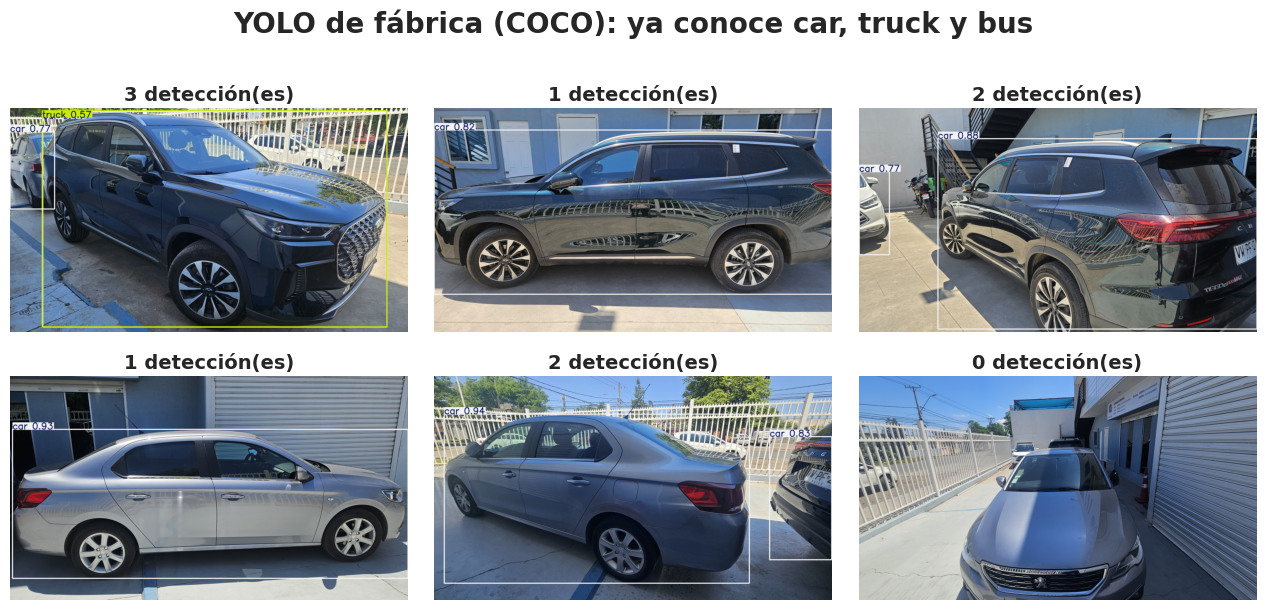

Gráfico guardado: f01_yolo_de_fabrica.png
Resultados guardados en: /content/resultados_c10/fabrica


,imagen,detecciones,clases
0,20261104_140739.jpg,3,"car, truck"
1,20261104_140752.jpg,1,car
2,20261104_140807.jpg,2,car
3,20261104_140818.jpg,1,car
4,20261104_140830.jpg,2,car
5,20261104_140840.jpg,0,
6,20261104_140930.jpg,3,car
7,20261104_140937.jpg,2,car
8,20261104_140942.jpg,2,"car, truck"
9,20261104_140949.jpg,1,car


In [10]:
# ============================================================
# PARTE 2B · Probarlo con fotos
# ============================================================
CARPETA_EJEMPLOS = BASE / "ejemplos"
ZIP_EJEMPLOS = BASE / "ejemplos.zip"                    # opcional: tus fotos comprimidas en un ZIP
if not CARPETA_EJEMPLOS.exists() and not ZIP_EJEMPLOS.exists() and PARAMETROS.get("drive_ejemplos"):
    import gdown                                        # [Proyecto] fotos y videos grabados por el grupo
    gdown.download_folder(id=PARAMETROS["drive_ejemplos"], output=str(CARPETA_EJEMPLOS), quiet=True)
if ZIP_EJEMPLOS.exists() and not CARPETA_EJEMPLOS.exists():
    with zipfile.ZipFile(ZIP_EJEMPLOS) as z:
        z.extractall(CARPETA_EJEMPLOS)
EJEMPLOS = sorted(p for p in CARPETA_EJEMPLOS.rglob("*")
                  if p.suffix.lower() in EXTENSIONES and "__MACOSX" not in str(p)) if CARPETA_EJEMPLOS.exists() else []
if not EJEMPLOS:                                        # sin fotos propias: dos fotos de Ultralytics
    CARPETA_EJEMPLOS.mkdir(exist_ok=True)
    for archivo in ["bus.jpg", "zidane.jpg"]:
        urllib.request.urlretrieve(f"https://ultralytics.com/images/{archivo}", CARPETA_EJEMPLOS / archivo)
    EJEMPLOS = listar_imagenes(CARPETA_EJEMPLOS)
print("Fotos de ejemplo:", [p.name for p in EJEMPLOS])

tabla_fabrica = predecir_imagenes(PARAMETROS["modelo_base"], EJEMPLOS, RESULTADOS / "fabrica",
                                  "YOLO de fábrica (COCO): ya conoce car, truck y bus",
                                  "f01_yolo_de_fabrica.png")
tabla_fabrica

---
# Parte 3 · El dataset: imágenes, cajas y el archivo YAML

Un dataset en formato YOLO son tres piezas:

1. Una carpeta `images/` con las fotos, separada en `train`, `val` y `test`.
2. Una carpeta `labels/` con **un archivo `.txt` por foto**, con el mismo nombre. Cada línea es una caja: `clase x_centro y_centro ancho alto`, todo dividido por el tamaño de la imagen (números entre 0 y 1).
3. Un archivo **`data.yaml`** que dice dónde están las carpetas y cómo se llama cada clase.

**Nuestro dataset:** Vehicles-OpenImages v1, descargado de Roboflow como ZIP en formato YOLO26. Según Roboflow trae **627 imágenes** (439 Train / 125 Validation / 63 Test), redimensionadas a 416×416 y **sin aumentos**. Sus imágenes vienen de Open Images (Google).

**Lo que encontramos al revisar el ZIP:**

- **Cada imagen viene duplicada:** el ZIP trae 878 / 250 / 126 archivos, el doble de lo declarado. Las dos copias tienen los mismos bytes y la misma etiqueta; solo cambia el sufijo que agrega Roboflow al nombre (`<id>_jpg.rf.<hash>.jpg`). Las copias siempre están **en el mismo split**, así que no hay fuga entre Train y Test, pero contarían cada imagen dos veces (en los conteos, en el entrenamiento y en las métricas). La Parte 3A-bis deja una copia por imagen. **No re-repartimos nada:** conservamos la partición original.
- **Cada imagen tiene una sola clase anotada:** el autor bajó las fotos de Open Images clase por clase. Un auto que aparece de fondo en una foto de buses puede no estar anotado.


In [11]:
# ============================================================
# PARTE 3A · El dataset: el ZIP de Roboflow (desde el notebook, el selector de archivos o Drive)
# ============================================================
if PARAMETROS["dataset_zip"]:
    # SU PROYECTO: el ZIP de Roboflow (Download Dataset → YOLO → Download zip to computer)
    ZIP_DATOS = Path(PARAMETROS["dataset_zip"])
    if not ZIP_DATOS.exists() and PARAMETROS.get("drive_id"):  # [Proyecto] respaldo: bajarlo de nuestro Drive
        import gdown                                            # viene instalado en Colab
        gdown.download(id=PARAMETROS["drive_id"], output=str(ZIP_DATOS), quiet=False)
    if str(ZIP_DATOS).startswith("/content/drive"):          # si lo dejaron en Google Drive
        from google.colab import drive
        drive.mount("/content/drive")
    if not ZIP_DATOS.exists() and Path("/content").exists():  # en Colab se abre el selector de archivos
        from google.colab import files
        print("Elige el ZIP del dataset en tu computador...")
        ZIP_DATOS = BASE / next(iter(files.upload()))
    ORIGEN = descomprimir_dataset(ZIP_DATOS, BASE / "datos_zip")
else:
    # (de la plantilla) sin ZIP se usaría el dataset de Kaggle; en nuestro proyecto no entra aquí
    import kagglehub
    os.environ.setdefault("KAGGLEHUB_CACHE", str(BASE / "kagglehub"))     # descarga junto al notebook
    try:
        ORIGEN = Path(kagglehub.dataset_download(PARAMETROS["dataset_kaggle"]))
    except Exception as error:
        print("Kaggle pidió autenticación:", type(error).__name__)
        os.environ["KAGGLE_API_TOKEN"] = getpass.getpass("Pega tu token de Kaggle (no se mostrará): ")
        ORIGEN = Path(kagglehub.dataset_download(PARAMETROS["dataset_kaggle"]))
print("Dataset original en:", ORIGEN)
for carpeta in sorted(p for p in ORIGEN.rglob("*") if p.is_dir()):
    n = len(list(carpeta.glob("*.*")))
    if n:
        print(f"  {carpeta.relative_to(ORIGEN)}: {n} archivos")

Downloading...
From (original): https://drive.google.com/uc?id=1IXm0Kp_fM0Of_XMeQsPIXvQZnNwc3Tdm
From (redirected): https://drive.google.com/uc?id=1IXm0Kp_fM0Of_XMeQsPIXvQZnNwc3Tdm&confirm=t&uuid=37238b89-20b5-4e09-a75f-30db9e3ab1d7
To: /content/Vehicles-OpenImages.v1-416x416.yolo26.zip
100%|██████████| 40.2M/40.2M [00:00<00:00, 117MB/s]


Dataset descomprimido en: /content/datos_zip
  train: 878 imágenes
  val: 250 imágenes
  test: 126 imágenes
Dataset original en: /content/datos_zip
  test/images: 126 archivos
  test/labels: 126 archivos
  train/images: 878 archivos
  train/labels: 878 archivos
  valid/images: 250 archivos
  valid/labels: 250 archivos


In [12]:
# ============================================================
# PARTE 3A-bis · [Proyecto] Quitar las imágenes duplicadas del ZIP
# ============================================================
# Roboflow nombra cada archivo como <id de Open Images>_jpg.rf.<hash>.jpg.
# Agrupamos por el id (lo que va antes de "_jpg.rf."), comprobamos que las copias
# sean idénticas y dejamos una sola por grupo, dentro del mismo split.
import hashlib
from collections import defaultdict

def huella(ruta):
    """md5 del archivo: dos copias idénticas tienen la misma huella."""
    return hashlib.md5(Path(ruta).read_bytes()).hexdigest()

ids_por_split, filas_dup = {}, []
for split in ("train", "val", "test"):
    carpeta_img, carpeta_lbl = buscar_split(ORIGEN, split)
    grupos = defaultdict(list)
    for img in listar_imagenes(carpeta_img):
        grupos[img.name.split("_jpg.rf.")[0]].append(img)
    borradas = 0
    for copias in grupos.values():
        base = copias[0]
        for img in copias[1:]:
            lbl_base = Path(carpeta_lbl) / f"{base.stem}.txt"
            lbl = Path(carpeta_lbl) / f"{img.stem}.txt"
            assert huella(img) == huella(base), f"{img.name} no es idéntica a {base.name}"
            assert sorted(lbl.read_text().split()) == sorted(lbl_base.read_text().split()), f"etiquetas distintas: {img.name}"
            img.unlink()
            lbl.unlink()
            borradas += 1
    ids_por_split[split] = set(grupos)
    filas_dup.append({"Split": split, "Archivos en el ZIP": len(grupos) + borradas,
                      "Duplicados borrados": borradas, "Imágenes únicas": len(grupos)})

# Comprobación de fuga: ninguna foto original puede estar en dos splits
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    comunes = ids_por_split[a] & ids_por_split[b]
    print(f"Fotos compartidas entre {a} y {b}: {len(comunes)}")
    assert not comunes, "Hay fuga entre splits"

tabla_duplicados = pd.DataFrame(filas_dup).set_index("Split")
NUMEROS["duplicados"] = tabla_duplicados.to_dict()
tabla_duplicados


Fotos compartidas entre train y val: 0
Fotos compartidas entre train y test: 0
Fotos compartidas entre val y test: 0


,Archivos en el ZIP,Duplicados borrados,Imágenes únicas
Split,,,
train,878,439,439
val,250,125,125
test,126,63,63


In [13]:
# ============================================================
# PARTE 3B · Train, Validation y Test + data.yaml
# ============================================================
if PARAMETROS["dataset_zip"]:
    NOMBRES = leer_nombres(ORIGEN / "data.yaml")               # las clases salen del data.yaml del ZIP
    print("Clases del ZIP:", NOMBRES)
    if PARAMETROS["clases"]:                                   # quedarse solo con 1 a 3 clases
        filtrar_clases(ORIGEN, BASE / "datos_filtrados", PARAMETROS["clases"])
        ORIGEN, NOMBRES = BASE / "datos_filtrados", dict(enumerate(PARAMETROS["clases"]))
DATA_YAML = crear_dataset_de_trabajo(ORIGEN, DATOS, NOMBRES, PARAMETROS["fraccion_test"], SEMILLA)
print("\nContenido de data.yaml:\n")
print(DATA_YAML.read_text(encoding="utf-8"))

conteo = contar_dataset(DATOS, NOMBRES)
# [Proyecto] Las imágenes que solo tenían Ambulance o Motorcycle quedan sin cajas.
# filtrar_clases las conserva como "fondo" (ejemplos de "aquí no hay Car, Truck ni Bus"):
# aparecen en la columna "Imágenes sin objetos".
NUMEROS["conteo"] = conteo.to_dict()
conteo

Clases del ZIP: {0: 'Ambulance', 1: 'Bus', 2: 'Car', 3: 'Motorcycle', 4: 'Truck'}
Dataset filtrado en: /content/datos_filtrados
       Imágenes  Cajas  Imágenes sin objetos  Car  Truck  Bus
Split                                                        
train       439    652                   122  457     96   99
val         125    172                    46  119     30   23
test         63    104                    15   75     10   19
El dataset ya trae train, val y test: se conservan.
Dataset de trabajo en: /content/datos_proyecto

Contenido de data.yaml:

path: /content/datos_proyecto
train: images/train
val: images/val
test: images/test
names:
  0: Car
  1: Truck
  2: Bus



,Imágenes,Cajas,Imágenes sin objetos,Car,Truck,Bus
Split,,,,,,
train,439,652,122,457,96,99
val,125,172,46,119,30,23
test,63,104,15,75,10,19


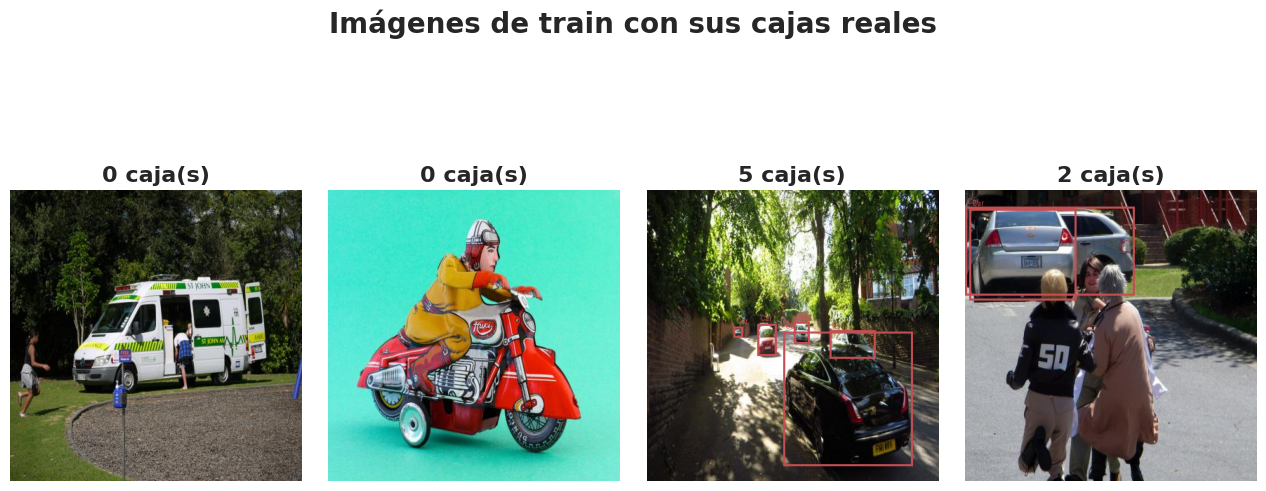

Gráfico guardado: f02_muestras_con_cajas.png


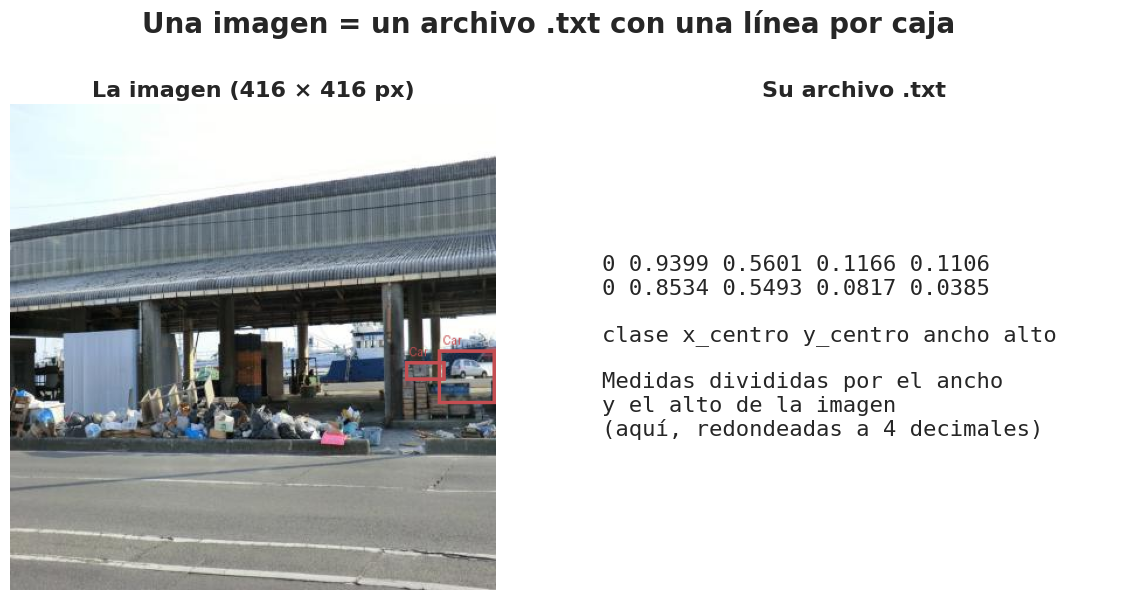

Gráfico guardado: f03_una_etiqueta_yolo.png


,Imágenes con Car,Imágenes con Truck,Imágenes con Bus
Split,,,
train,184,65,68
val,45,19,15
test,30,7,11


In [14]:
# ============================================================
# PARTE 3C · Ver las cajas: así se ve una etiqueta
# ============================================================
mostrar_muestras(DATOS, "train", NOMBRES, n=4, nombre="f02_muestras_con_cajas.png")
ruta_ejemplo, lineas_ejemplo = explicar_etiqueta(DATOS, "train", NOMBRES, nombre="f03_una_etiqueta_yolo.png")
NUMEROS["etiqueta_ejemplo"] = {"imagen": ruta_ejemplo.name, "lineas": lineas_ejemplo}

# [Proyecto] Imágenes por clase (no solo cajas): cuántas fotos tienen al menos una caja de cada clase
filas = []
for split in ("train", "val", "test"):
    fila = {"Split": split}
    for i, n in NOMBRES.items():
        fila[f"Imágenes con {n}"] = sum(
            any(l.split() and int(l.split()[0]) == i for l in t.read_text().split("\n"))
            for t in (DATOS / "labels" / split).glob("*.txt"))
    filas.append(fila)
imagenes_por_clase = pd.DataFrame(filas).set_index("Split")
NUMEROS["imagenes_por_clase"] = imagenes_por_clase.to_dict()
imagenes_por_clase


---
# Parte 4 · Transfer learning

Igual que con MobileNetV2 en la clase 09: partimos de un modelo que ya sabe ver y **congelamos el backbone** (las primeras capas, que detectan bordes, texturas y formas). Solo se entrenan las capas finales, que aprenden a reconocer nuestras 3 clases de vehículos.

Como el dataset es chico usamos **todo el Train** (`fraccion_transfer = 1.0`), imágenes de 416 px (el tamaño en que las entrega Roboflow) y 30 épocas.

**Paciencia:** si durante 10 épocas seguidas el modelo no mejora en Validation, el entrenamiento se detiene y se queda con la mejor época. Seguir entrenando ahí solo sobreajusta (la pérdida de Train sigue bajando y la de Validation sube) y gasta tiempo de Colab. Con 30 épocas puede activarse: si pasa, se anota en qué época se detuvo.

Ultralytics guarda todo en `runs_c10/transfer_learning/`: los pesos (`weights/best.pt`), las métricas por época (`results.csv`) y sus gráficos.

In [15]:
# ============================================================
# PARTE 4A · Entrenamiento con el backbone congelado
# ============================================================
RUTA_TL, SEGUNDOS_TL, RUN_TL = entrenar(
    PARAMETROS["modelo_base"],                 # 1) partimos de los pesos de COCO
    "transfer_learning",
    epocas=PARAMETROS["epocas_transfer"],      # 2) pocas épocas
    fraccion=PARAMETROS["fraccion_transfer"],  # 3) una parte del Train
    congelar=PARAMETROS["capas_congeladas"],   # 4) backbone congelado
    horas=PARAMETROS["horas_maximas_transfer"],
)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datos_proyecto/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=10, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=transfer_learning, nbs=64, nms=None, opset=None, optimize=F

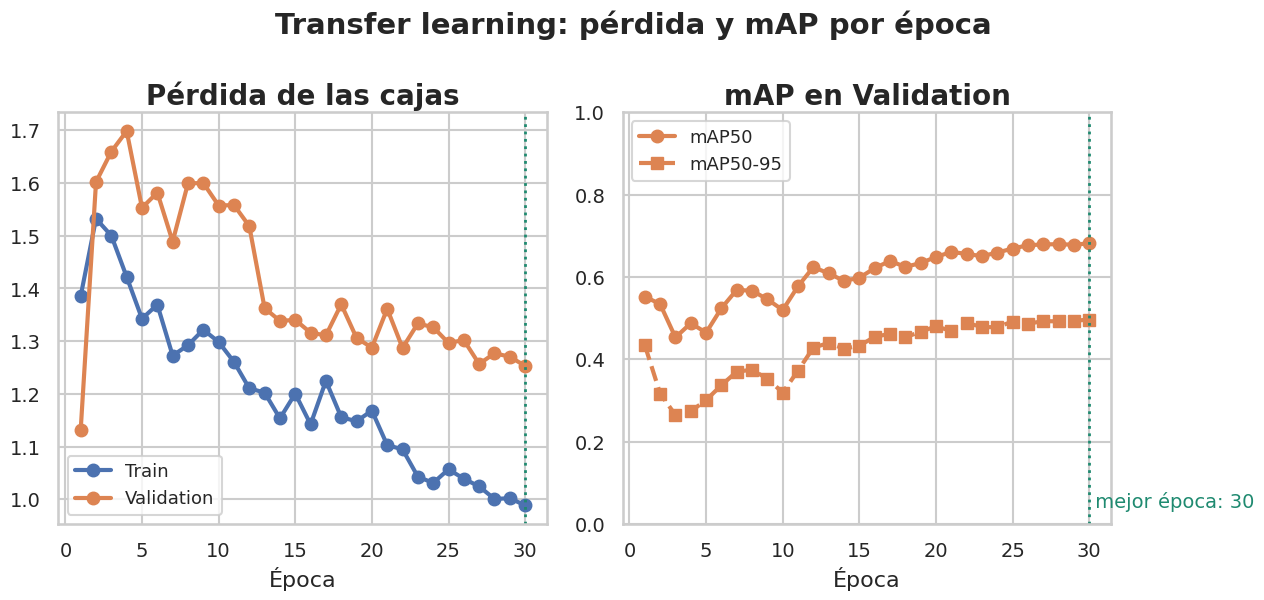

Gráfico guardado: f04_curvas_transfer.png
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 893.7±459.2 MB/s, size: 27.8 KB)
val: Scanning /content/datos_proyecto/labels/val.cache... 125 images, 46 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 125/125 47.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.8it/s 1.7s
                   all        125        172      0.677      0.607      0.682      0.497
Speed: 0.8ms preprocess, 3.7ms inference, 0.0ms loss, 2.4ms postprocess per image
Results saved to /content/runs_c10/eval_transfer_learning_val
transfer_learning en val: {'Precision': 0.677, 'Recall': 0.607, 'mAP50': 0.682, 'mAP50-95': 0.497}


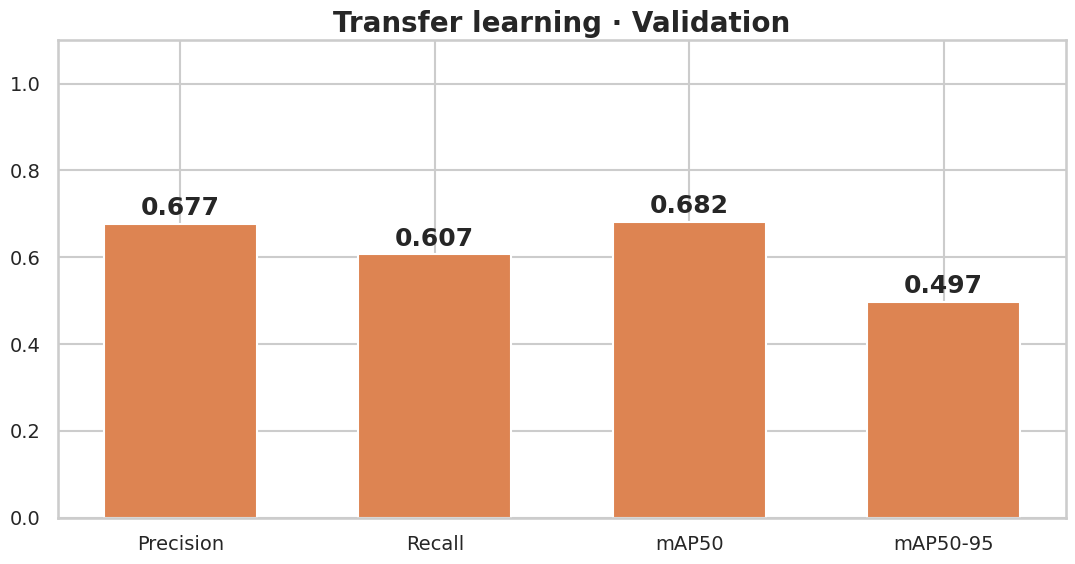

Gráfico guardado: f05_metricas_transfer_val.png


In [16]:
# ============================================================
# PARTE 4B · Curvas y métricas en Validation
# ============================================================
MEJOR_EPOCA_TL, EPOCAS_TL = graficar_curvas(RUN_TL, "Transfer learning: pérdida y mAP por época", "f04_curvas_transfer.png")
METRICAS_TL, EVAL_TL = evaluar(RUTA_TL, "val", "transfer_learning")
graficar_metricas(METRICAS_TL, "Transfer learning · Validation", "f05_metricas_transfer_val.png")
NUMEROS["transfer_learning"] = {"minutos": SEGUNDOS_TL / 60, "epocas": EPOCAS_TL,
                                "mejor_epoca": MEJOR_EPOCA_TL, "validation": METRICAS_TL}

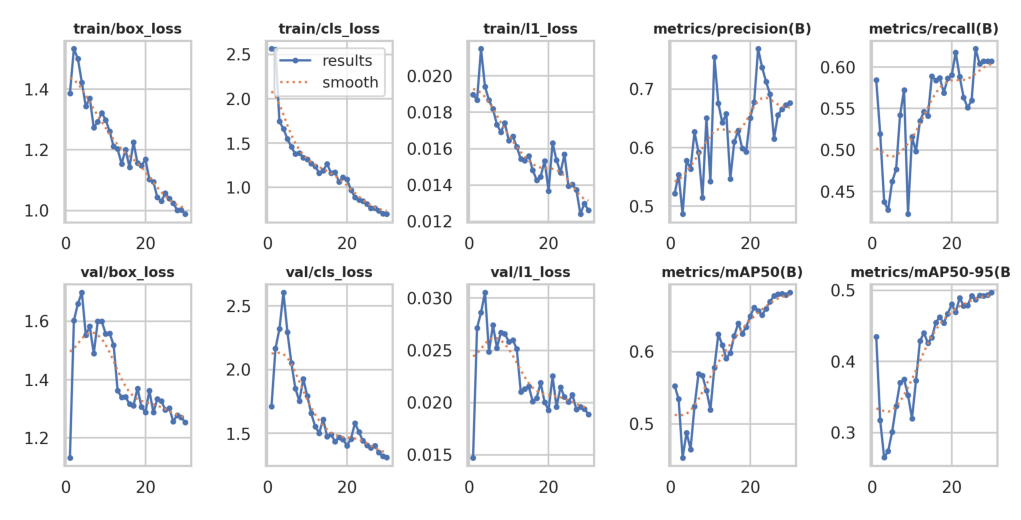

Gráfico guardado: f06_results_ultralytics.png


In [17]:
# ============================================================
# PARTE 4C · El resumen que arma Ultralytics
# ============================================================
copiar_figura(RUN_TL / "results.png", "f06_results_ultralytics.png")

---
# Parte 5 · ¿Cómo se mide un detector?

En clasificación bastaba comparar la clase predicha con la real. En detección también importa **dónde** quedó la caja.

- **IoU** (*Intersection over Union*): cuánto se superpone la caja predicha con la real. 1 es perfecta y 0, que no se tocan. Una detección cuenta como **acierto** si su IoU llega a un umbral, normalmente **0,5**.
- **Precision**: de todas las cajas que dibujó el modelo, qué parte era un vehículo de verdad (y de la clase correcta). Baja cuando inventa vehículos.
- **Recall**: de todos los vehículos reales, qué parte encontró. Baja cuando se le escapan.
- Las dos dependen de la **confianza mínima**: si se exige más confianza, el modelo inventa menos vehículos (sube precision), pero se le escapan más (baja recall). La curva precision-recall muestra ese equilibrio.
- **mAP50**: resume precision y recall en todos los niveles de confianza, con IoU de 0,5. Es la métrica más usada.
- **mAP50-95**: lo mismo, pero exigiendo cajas cada vez más ajustadas (IoU de 0,50 a 0,95). Siempre es menor que mAP50.

Ojo: la precision y el recall que reporta Ultralytics están calculados en la confianza que da el mejor equilibrio entre ambos. Por eso no coinciden con el conteo de la Parte 5B, que usa la confianza mínima de 0,25 con que se dibujan las cajas.

Con 3 clases, mAP es el **promedio del AP de cada clase**. Como `Car` tiene unas 4,6 veces más cajas que `Truck` o `Bus`, conviene mirar también la matriz de confusión (Partes 7B y 8C) para ver si los errores se concentran en una clase.


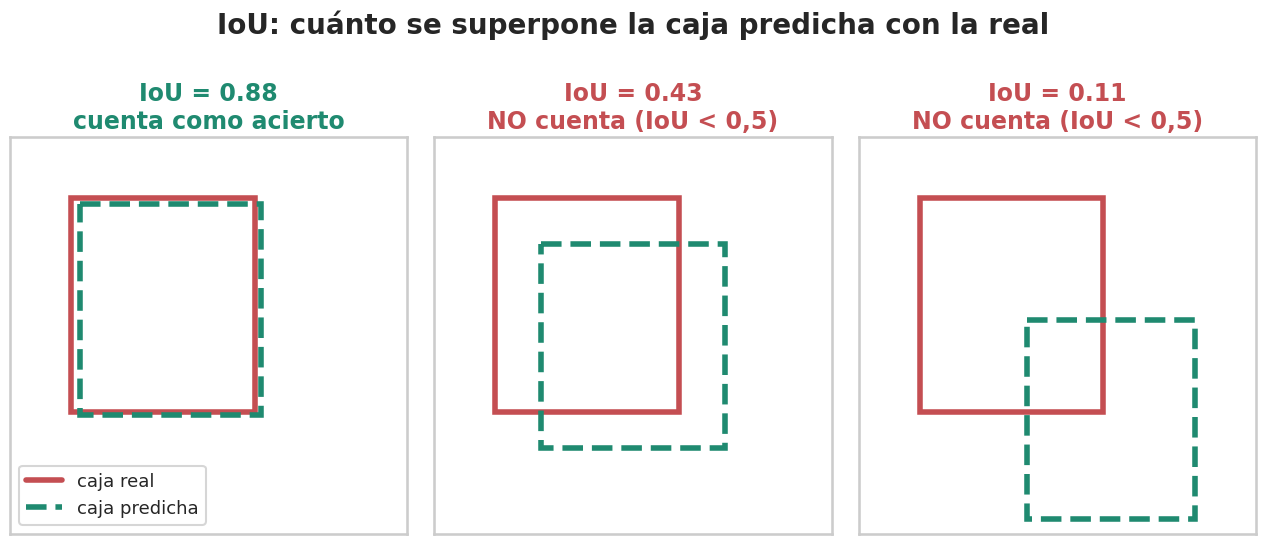

Gráfico guardado: f07_iou.png


In [18]:
# ============================================================
# PARTE 5A · IoU en un dibujo
# ============================================================
graficar_iou("f07_iou.png")

{'Aciertos': 102, 'Falsas detecciones': 45, 'Objetos perdidos': 70, 'Precision': 0.694, 'Recall': 0.593, 'Imágenes': 125}


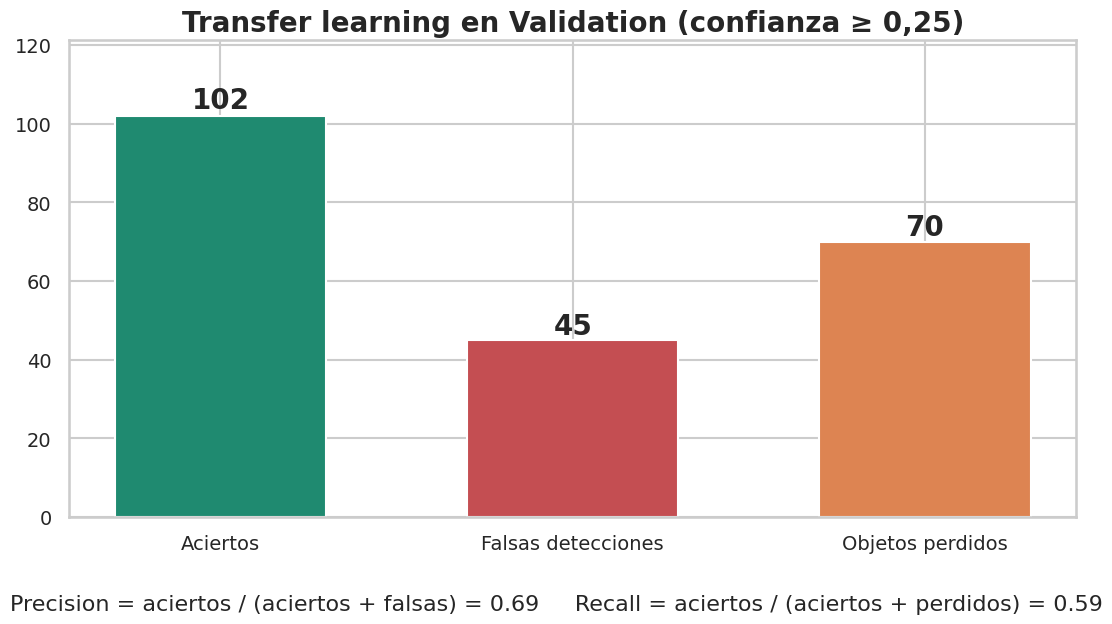

Gráfico guardado: f08_aciertos_falsas_perdidas.png


In [19]:
# ============================================================
# PARTE 5B · Aciertos, falsas detecciones y vehículos perdidos (con confianza 0,25)
# ============================================================
ACIERTOS_TL = contar_aciertos(RUTA_TL, DATOS, "val", NOMBRES, conf=PARAMETROS["confianza"])
graficar_aciertos(ACIERTOS_TL, "Transfer learning en Validation (confianza ≥ 0,25)", "f08_aciertos_falsas_perdidas.png")
NUMEROS["transfer_learning"]["aciertos_val"] = ACIERTOS_TL

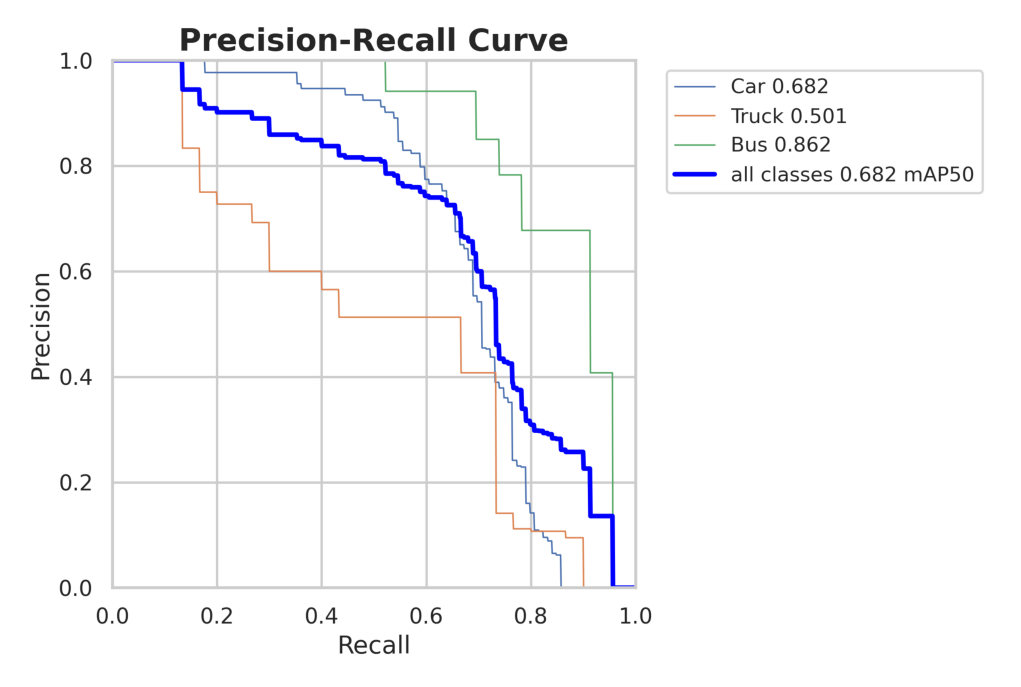

Gráfico guardado: f09_curva_pr.png


In [20]:
# ============================================================
# PARTE 5C · Curva precision-recall: qué pasa al mover la confianza mínima
# ============================================================
copiar_figura(EVAL_TL / "BoxPR_curve.png", "f09_curva_pr.png")

---
# Parte 6 · Fine tuning

Ahora **descongelamos todo** y seguimos entrenando desde el mejor modelo del transfer learning, con un **learning rate bajo** para ajustar sin romper lo aprendido. Es la misma idea de la clase 09.

**Ajustes tras una corrida de prueba, decididos solo con las curvas de Validation:**

- En la prueba, con `lr = 5e-4`, el mAP50-95 de Validation cayó de 0,43 (época 1) a 0,07 (época 4). Bajamos el learning rate a `1e-4`.
- Ultralytics hace un *warmup* (calentamiento) las 3 primeras épocas. Cuando elige el optimizador solo (`auto`, como en el transfer learning) pone `warmup_bias_lr = 0`; pero cuando le pedimos `AdamW` explícitamente deja el valor por defecto, **0,1**, que con AdamW es enorme para los sesgos (*bias*) y desarma el modelo al inicio. Por eso lo fijamos en 0, igual que hace el modo `auto`. Para pasar ese argumento agregamos `**otros` a la función `entrenar` (único cambio en la Parte 1).


In [21]:
# ============================================================
# PARTE 6A · Entrenamiento con todas las capas
# ============================================================
RUTA_FT, SEGUNDOS_FT, RUN_FT = entrenar(
    RUTA_TL,                                      # 1) partimos del mejor modelo anterior
    "fine_tuning",
    epocas=PARAMETROS["epocas_fine_tuning"],
    fraccion=PARAMETROS["fraccion_fine_tuning"],
    congelar=None,                                # 2) nada congelado
    optimizador="AdamW",                          # 3) optimizador explícito para que respete lr0
    lr0=PARAMETROS["lr_fine_tuning"],             # 4) learning rate bajo
    warmup_bias_lr=0.0,                           # 5) [Proyecto] sin el "calentamiento" de 0,1 en los sesgos (ver texto)
    horas=PARAMETROS["horas_maximas_fine_tuning"],
)

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=-1, bgr=0.0, box=7.5, cache=disk, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/datos_proyecto/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=20, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=416, iou=0.7, kobj=1.0, line_width=None, lr0=0.0001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=/content/runs_c10/transfer_learning/weights/best.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=fine_tuning, n

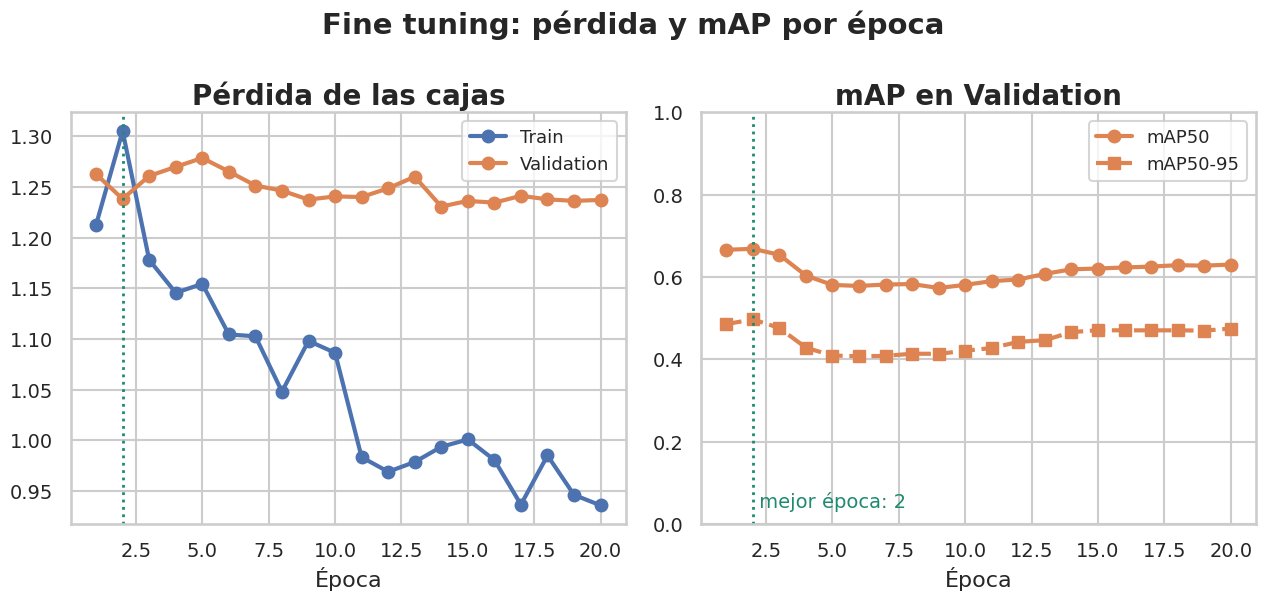

Gráfico guardado: f10_curvas_fine_tuning.png
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1442.6±569.4 MB/s, size: 31.3 KB)
val: Scanning /content/datos_proyecto/labels/val.cache... 125 images, 46 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 125/125 43.7Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 8/8 4.6it/s 1.8s
                   all        125        172       0.66      0.607      0.672        0.5
Speed: 1.1ms preprocess, 3.5ms inference, 0.0ms loss, 1.9ms postprocess per image
Results saved to /content/runs_c10/eval_fine_tuning_val
fine_tuning en val: {'Precision': 0.66, 'Recall': 0.607, 'mAP50': 0.672, 'mAP50-95': 0.5}


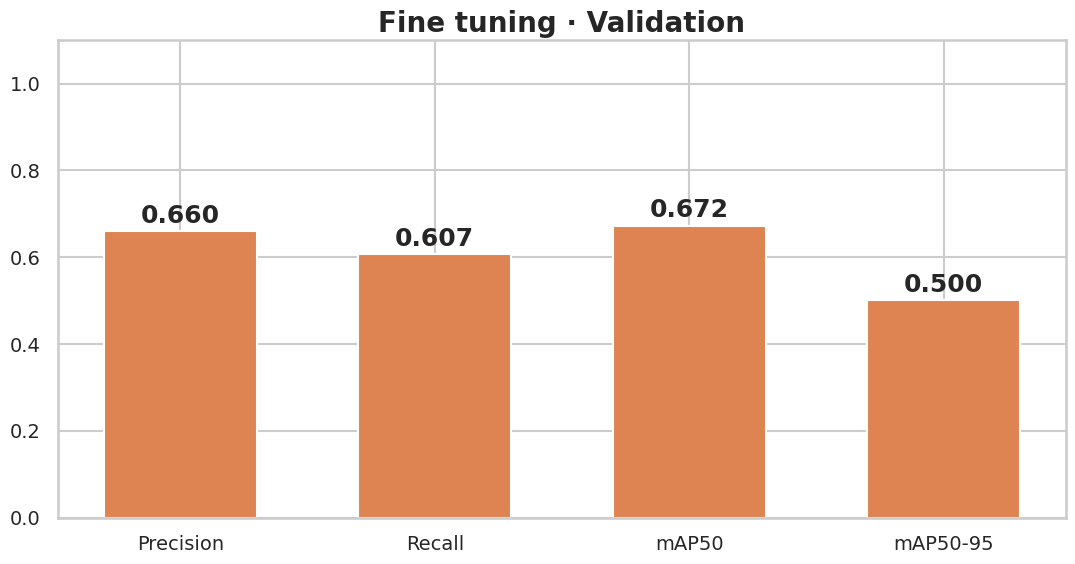

Gráfico guardado: f11_metricas_fine_tuning_val.png


In [22]:
# ============================================================
# PARTE 6B · Curvas y métricas en Validation
# ============================================================
MEJOR_EPOCA_FT, EPOCAS_FT = graficar_curvas(RUN_FT, "Fine tuning: pérdida y mAP por época", "f10_curvas_fine_tuning.png")
METRICAS_FT, EVAL_FT = evaluar(RUTA_FT, "val", "fine_tuning")
graficar_metricas(METRICAS_FT, "Fine tuning · Validation", "f11_metricas_fine_tuning_val.png")
NUMEROS["fine_tuning"] = {"minutos": SEGUNDOS_FT / 60, "epocas": EPOCAS_FT,
                          "mejor_epoca": MEJOR_EPOCA_FT, "validation": METRICAS_FT}

---
# Parte 7 · Comparar los modelos con Validation

**Regla, decidida antes de mirar Test:** nos quedamos con el modelo de **mayor mAP50-95 en Validation**.

**Por qué esta métrica:** mAP50-95 premia que las cajas queden bien ajustadas (no solo que toquen al vehículo) y promedia las 3 clases, así que no la domina `Car`, que es la clase con más ejemplos. Si los dos modelos empatan, gana el de mayor mAP50.


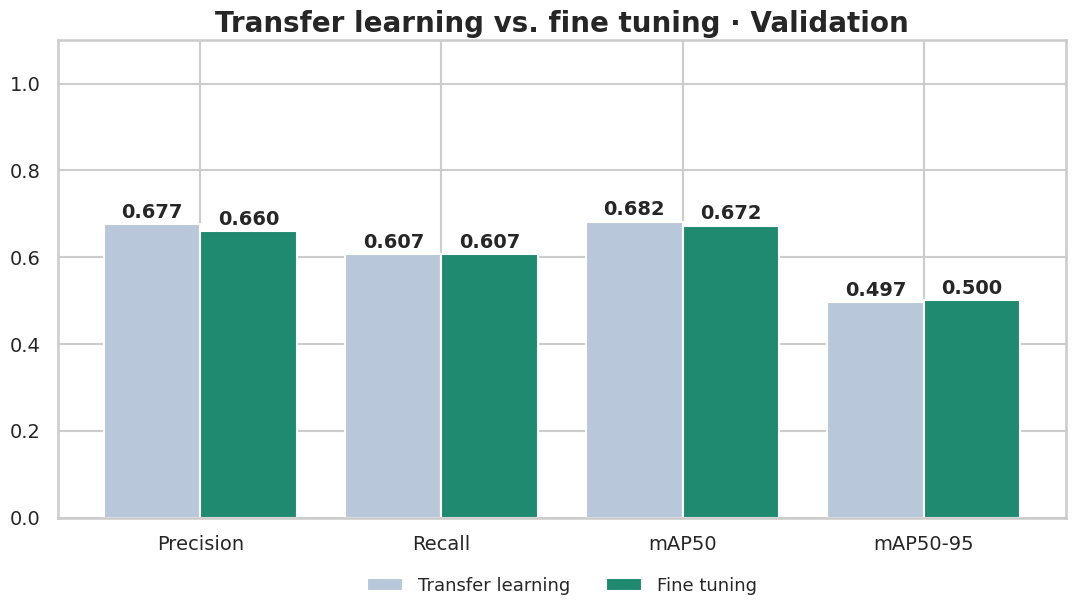

Gráfico guardado: f12_comparacion_validation.png
Modelo elegido: Fine tuning


In [23]:
# ============================================================
# PARTE 7A · Elegir con Validation
# ============================================================
CANDIDATOS = {"Transfer learning": (RUTA_TL, METRICAS_TL), "Fine tuning": (RUTA_FT, METRICAS_FT)}
ELEGIDO = max(CANDIDATOS, key=lambda k: (CANDIDATOS[k][1]["mAP50-95"], CANDIDATOS[k][1]["mAP50"]))  # desempate: mAP50
RUTA_ELEGIDO = CANDIDATOS[ELEGIDO][0]
comparar_modelos({k: v[1] for k, v in CANDIDATOS.items()}, "Transfer learning vs. fine tuning · Validation",
                 "f12_comparacion_validation.png", elegido=ELEGIDO)
print("Modelo elegido:", ELEGIDO)
NUMEROS["elegido"] = ELEGIDO

{'Aciertos': 105, 'Falsas detecciones': 57, 'Objetos perdidos': 67, 'Precision': 0.648, 'Recall': 0.61, 'Imágenes': 125}


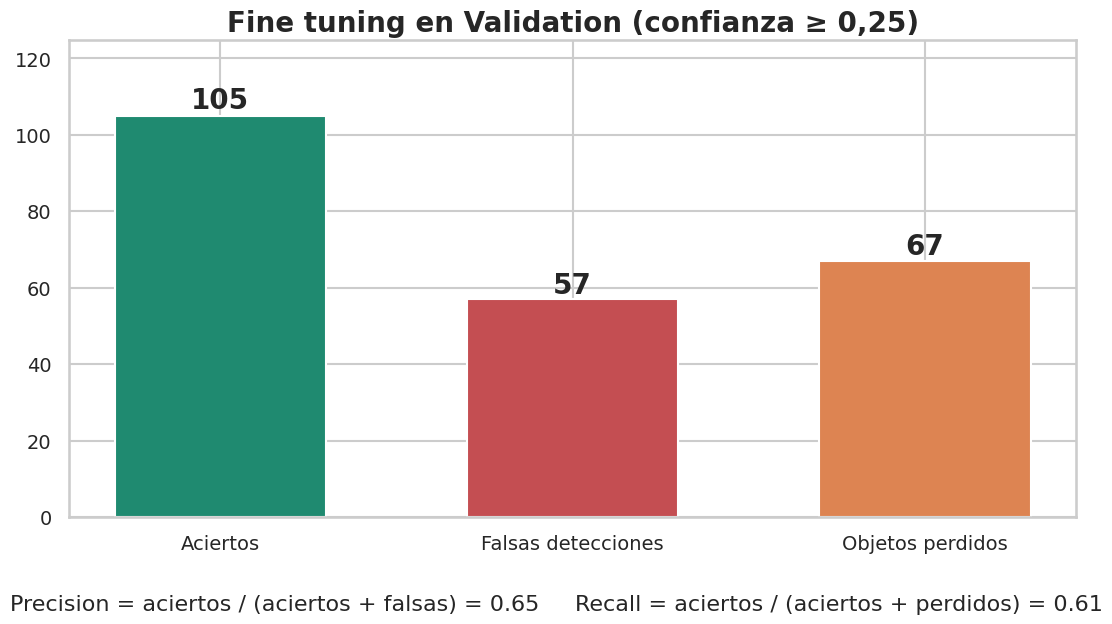

Gráfico guardado: f12b_aciertos_elegido_val.png


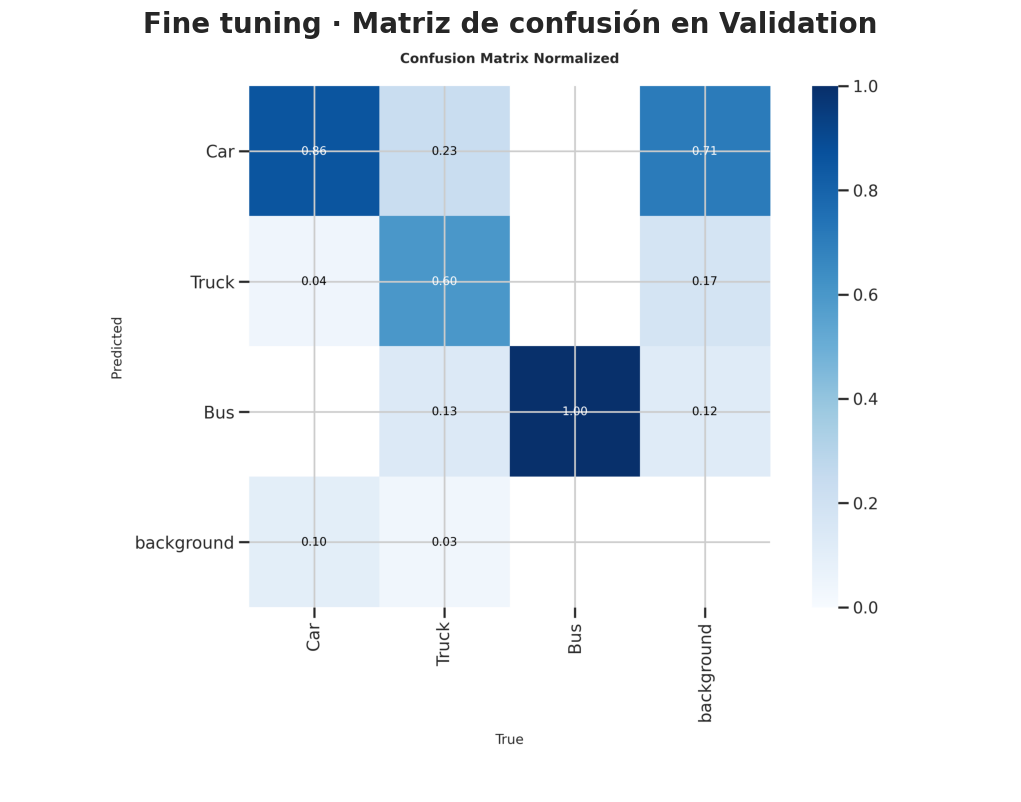

Gráfico guardado: f12c_confusion_val.png


In [24]:
# ============================================================
# PARTE 7B · [Proyecto] El modelo elegido en Validation: aciertos y matriz de confusión
# ============================================================
# El enunciado pide aciertos / falsas / perdidos al menos del modelo elegido.
# La Parte 5B los calculó para transfer learning; si ganó fine tuning, se calculan aquí.
EVAL_ELEGIDO_VAL = EVAL_TL if ELEGIDO == "Transfer learning" else EVAL_FT
if ELEGIDO == "Transfer learning":
    ACIERTOS_ELEGIDO = ACIERTOS_TL
else:
    ACIERTOS_ELEGIDO = contar_aciertos(RUTA_ELEGIDO, DATOS, "val", NOMBRES, conf=PARAMETROS["confianza"])
    graficar_aciertos(ACIERTOS_ELEGIDO, f"{ELEGIDO} en Validation (confianza ≥ 0,25)", "f12b_aciertos_elegido_val.png")
NUMEROS["aciertos_elegido_val"] = ACIERTOS_ELEGIDO

# Matriz de confusión normalizada: filas/columnas por clase + "background" (fondo).
# Muestra si se confunden Truck y Bus, o si se pierden vehículos (columna background).
copiar_figura(EVAL_ELEGIDO_VAL / "confusion_matrix_normalized.png", "f12c_confusion_val.png",
              f"{ELEGIDO} · Matriz de confusión en Validation")


---
# Parte 8 · Evaluación final con Test

Test se usa **una sola vez**, con el modelo elegido y **al mismo tamaño de imagen del entrenamiento**: si se evalúa a otro tamaño, las métricas cambian.

Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 930.6±452.9 MB/s, size: 27.2 KB)
val: Scanning /content/datos_proyecto/labels/test... 63 images, 15 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 63/63 2.1Kit/s 0.0s
val: New cache created: /content/datos_proyecto/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.5it/s 1.6s
                   all         63        104      0.815      0.656      0.737      0.538
Speed: 1.4ms preprocess, 6.1ms inference, 0.0ms loss, 4.3ms postprocess per image
Results saved to /content/runs_c10/eval_elegido_test
elegido en test: {'Precision': 0.815, 'Recall': 0.656, 'mAP50': 0.737, 'mAP50-95': 0.538}


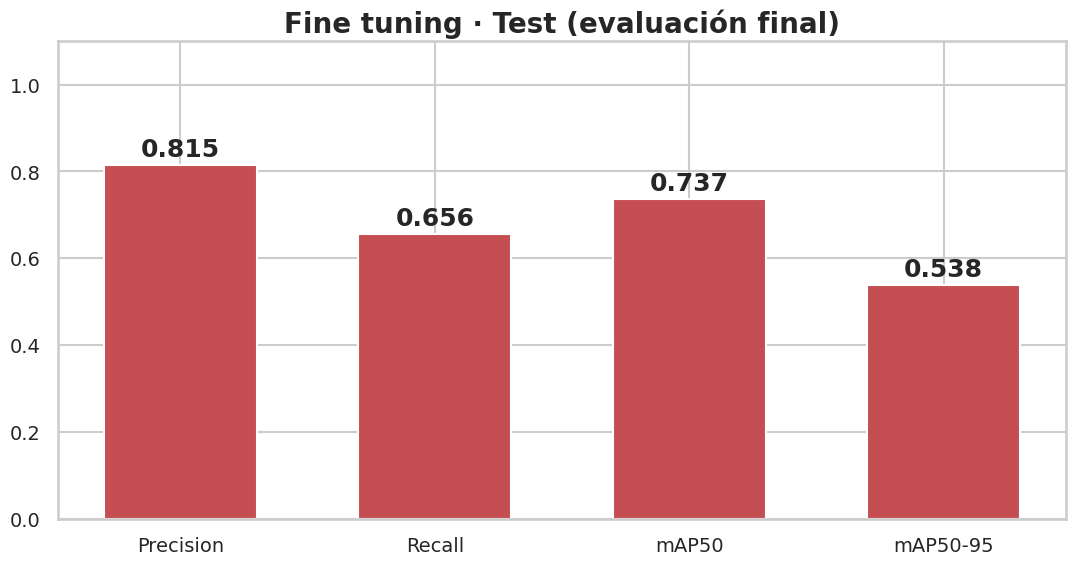

Gráfico guardado: f13_metricas_test.png


In [25]:
# ============================================================
# PARTE 8A · Métricas en Test
# ============================================================
METRICAS_TEST, EVAL_TEST = evaluar(RUTA_ELEGIDO, "test", "elegido")
graficar_metricas(METRICAS_TEST, f"{ELEGIDO} · Test (evaluación final)", "f13_metricas_test.png", color=TEST)
NUMEROS["test"] = METRICAS_TEST

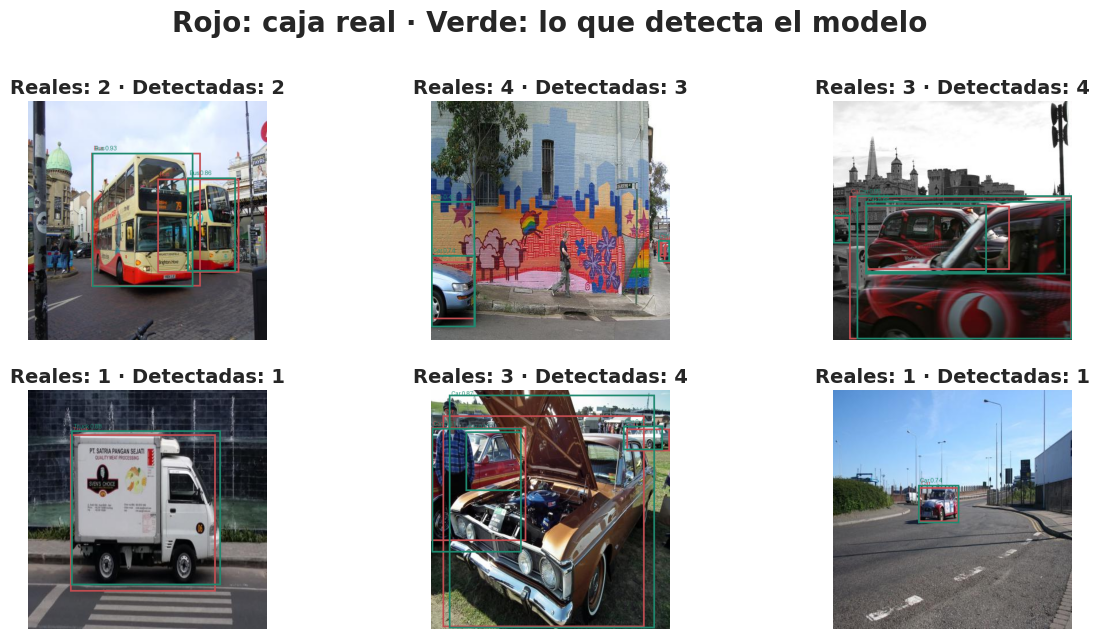

Gráfico guardado: f14_real_vs_detectado_test.png


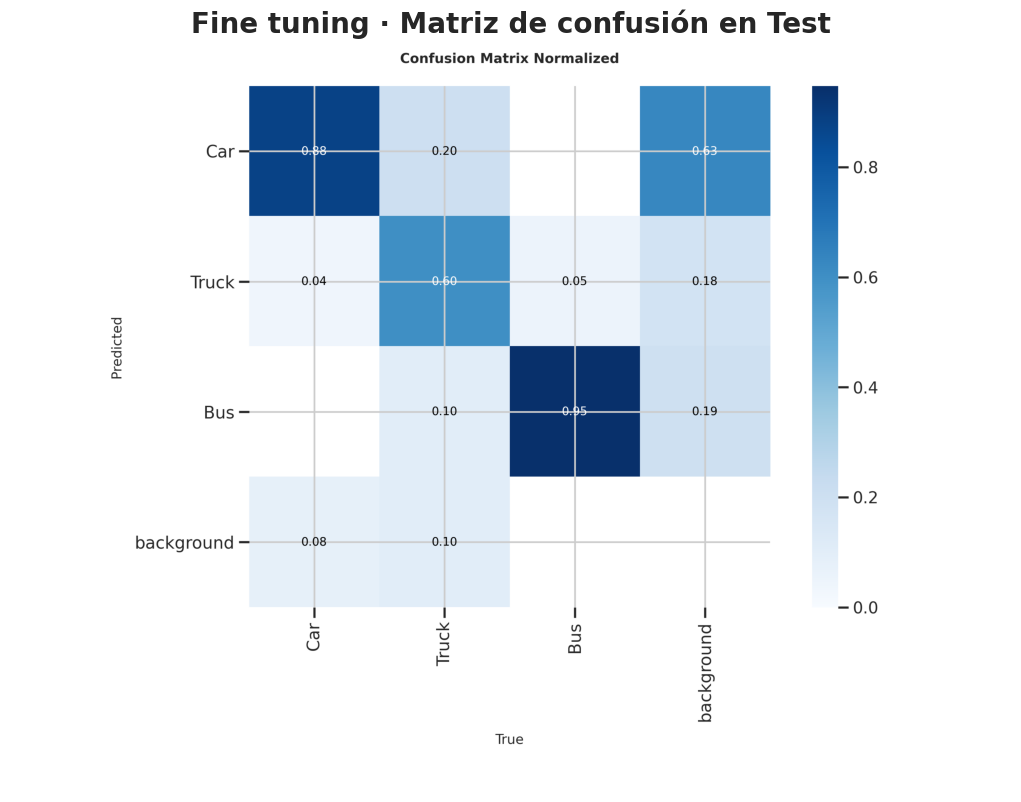

Gráfico guardado: f14b_confusion_test.png


In [26]:
# ============================================================
# PARTE 8B · Cajas reales vs. detectadas en Test
# ============================================================
galeria_real_vs_predicho(RUTA_ELEGIDO, DATOS, "test", NOMBRES, n=6, nombre="f14_real_vs_detectado_test.png")

# [Proyecto] Matriz de confusión en Test (la generó la evaluación de la Parte 8A)
copiar_figura(EVAL_TEST / "confusion_matrix_normalized.png", "f14b_confusion_test.png",
              f"{ELEGIDO} · Matriz de confusión en Test")

## [Proyecto] Parte 8C · Buscar los tres tipos de error en Test

La galería anterior elige imágenes al azar, y puede que no muestre los errores que pide el enunciado. Esta celda recorre **todo Test** con el modelo elegido (confianza 0,25, igual que la Parte 5B) y clasifica cada caja:

- **Objeto perdido:** una caja real que ninguna detección cubre (IoU < 0,5 con todas).
- **Falsa detección:** una detección que no cubre ninguna caja real (IoU < 0,1 con todas).
- **Clase confundida:** una detección bien ubicada (IoU ≥ 0,5) pero con otra clase, por ejemplo un `Bus` detectado como `Truck`.
- **Caja mal ubicada:** una detección de la clase correcta que solo toca a medias la caja real (0,1 ≤ IoU < 0,5).

Luego muestra la imagen con más errores de cada tipo (rojo: real, verde: detectado). **Esto no es elegir con Test:** el modelo ya está elegido; solo buscamos ejemplos para el análisis de errores.

Al comentar una falsa detección, revisen si en realidad es un vehículo **sin anotar** (recuerden que cada foto tiene una sola clase etiquetada).


Errores en Test (todas las imágenes):
perdidos        35
falsas           6
confundidas      2
mal ubicadas     8


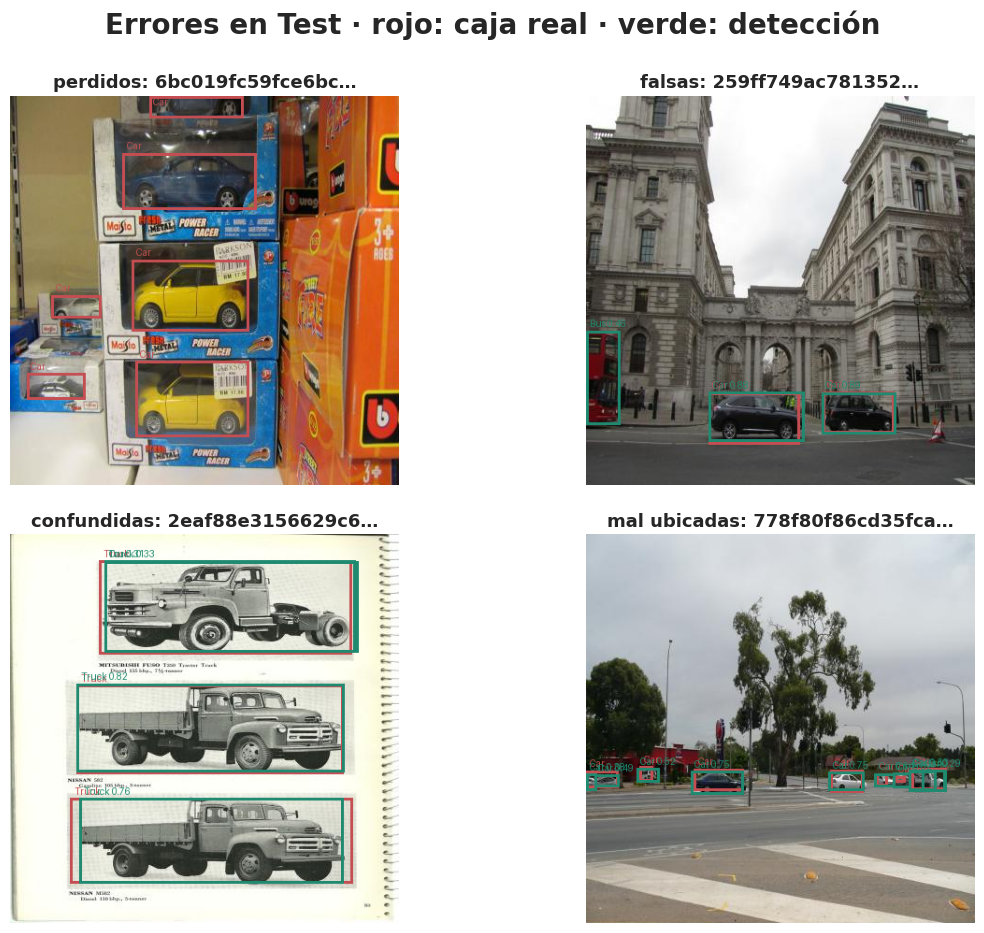

Gráfico guardado: f14c_errores_test.png


,imagen,reales,detectadas,perdidos,falsas,confundidas,mal ubicadas
21,6bc019fc59fce6bc_jpg.rf.VJAhyBJnfIldtscisZ3p.jpg,6,0,6,0,0,0
18,621edf1632f6f63c_jpg.rf.caa3c8e665a2cccfbaf94d...,4,3,3,0,0,2
23,6dce4caa5b30c32a_jpg.rf.99b1738867fe889250ccde...,4,1,3,0,0,0
56,d66aabbb1f7299cc_jpg.rf.27774c8e4188c1c8b62075...,3,0,3,0,0,0
59,f00ec0093e986e99_jpg.rf.788065bc895796a1b381a6...,6,3,3,0,0,0
15,58163cb625c30451_jpg.rf.f224c9704e2d5d99e2da9e...,3,1,2,0,0,0
27,778f80f86cd35fca_jpg.rf.74dd531b37bb62f4d40e62...,7,10,2,0,0,3
37,9ca8e20e0869f289_jpg.rf.4bb7001185dba72f41b354...,2,1,2,0,0,1
51,c0a105b4fe3a7c55_jpg.rf.28745179cd0f87dc9cae88...,4,4,1,1,0,0
10,3429c6851095a4c3_jpg.rf.2921b5c17bda3bda8b69e0...,3,2,1,0,0,0


In [27]:
# ============================================================
# PARTE 8C · [Proyecto] Objetos perdidos, falsas detecciones, confusiones y cajas mal ubicadas
# ============================================================
def clasificar_errores(ruta_pesos, raiz, split, conf):
    """Para cada imagen, cuenta los cuatro tipos de error (ver la celda anterior)."""
    modelo = YOLO(ruta_pesos)
    filas = []
    for ruta in listar_imagenes(Path(raiz) / "images" / split):
        img = cargar_imagen(ruta)
        reales = leer_cajas(Path(raiz) / "labels" / split / f"{ruta.stem}.txt", img.width, img.height)
        r = modelo.predict(img, imgsz=PARAMETROS["imgsz"], conf=conf, device=DISPOSITIVO, verbose=False)[0]
        pred = [(int(c), *xyxy) for c, xyxy in zip(r.boxes.cls.tolist(), r.boxes.xyxy.tolist())]
        cubiertas = set()                      # cajas reales que alguna detección cubre con IoU >= 0,5
        falsas = confundidas = mal_ubicadas = 0
        for cp, *bp in pred:
            ious = [(iou(bp, br), j, cr) for j, (cr, *br) in enumerate(reales)]
            mejor, j, cr = max(ious) if ious else (0, None, None)
            if mejor >= 0.5:
                cubiertas.add(j)
                confundidas += cr != cp
            elif mejor >= 0.1:
                mal_ubicadas += cr == cp
            else:
                falsas += 1
        filas.append({"imagen": ruta.name, "reales": len(reales), "detectadas": len(pred),
                      "perdidos": len(reales) - len(cubiertas), "falsas": falsas,
                      "confundidas": confundidas, "mal ubicadas": mal_ubicadas})
    return pd.DataFrame(filas)


def mostrar_error(ruta_pesos, raiz, split, nombre_imagen, titulo, ax):
    """Una imagen con sus cajas reales (rojo) y detectadas (verde)."""
    ruta = Path(raiz) / "images" / split / nombre_imagen
    img = cargar_imagen(ruta)
    reales = leer_cajas(Path(raiz) / "labels" / split / f"{ruta.stem}.txt", img.width, img.height)
    r = YOLO(ruta_pesos).predict(img, imgsz=PARAMETROS["imgsz"], conf=PARAMETROS["confianza"],
                                 device=DISPOSITIVO, verbose=False)[0]
    pred = [(int(c), *xyxy) for c, xyxy in zip(r.boxes.cls.tolist(), r.boxes.xyxy.tolist())]
    img = dibujar_cajas(img, reales, NOMBRES, TEST)
    img = dibujar_cajas(img, pred, NOMBRES, MEJOR, confianzas=r.boxes.conf.tolist())
    ax.imshow(img)
    ax.set_title(titulo, fontsize=13)
    ax.axis("off")


ERRORES_TEST = clasificar_errores(RUTA_ELEGIDO, DATOS, "test", PARAMETROS["confianza"])
resumen = ERRORES_TEST[["perdidos", "falsas", "confundidas", "mal ubicadas"]].sum()
print("Errores en Test (todas las imágenes):")
print(resumen.to_string())
NUMEROS["errores_test"] = resumen.to_dict()

ejemplos_error = []
for tipo in ["perdidos", "falsas", "confundidas", "mal ubicadas"]:
    candidatas = ERRORES_TEST[ERRORES_TEST[tipo] > 0].sort_values(tipo, ascending=False)
    if len(candidatas):
        ejemplos_error.append((tipo, candidatas.iloc[0]["imagen"]))
    else:
        print(f"No hubo ningún caso de '{tipo}' en Test.")

if ejemplos_error:
    estilo()
    fig, ejes = grilla(len(ejemplos_error), columnas=2, alto_fila=4.5)
    for ax, (tipo, nombre_img) in zip(ejes, ejemplos_error):
        mostrar_error(RUTA_ELEGIDO, DATOS, "test", nombre_img, f"{tipo}: {nombre_img[:16]}…", ax)
    fig.suptitle("Errores en Test · rojo: caja real · verde: detección", fontsize=20, fontweight="bold")
    fig.tight_layout()
    guardar_figura("f14c_errores_test.png")

# Tabla completa, por si quieren elegir otro ejemplo para el informe
ERRORES_TEST.to_csv(RESULTADOS / "errores_test.csv", index=False)
ERRORES_TEST.sort_values(["perdidos", "falsas", "confundidas"], ascending=False).head(10)


---
# Parte 9 · Usar el modelo con imágenes y con video

Entrenar necesita GPU. **Usar** el modelo entrenado, no tanto: cada imagen toma milisegundos y funciona también en la CPU de un notebook.

- **Imágenes:** 14 fotos tomadas por el grupo el 4 de noviembre de 2026, que se bajan solas de nuestra carpeta de Drive a `ejemplos/` (Parte 2B). Los resultados quedan en `resultados_c10/imagenes/`.
- **Video:** nuestros 2 videos grabados (están en la misma carpeta de Drive). Quedan procesados en `resultados_c10/video_detectado_1.mp4` y `video_detectado_2.mp4`.



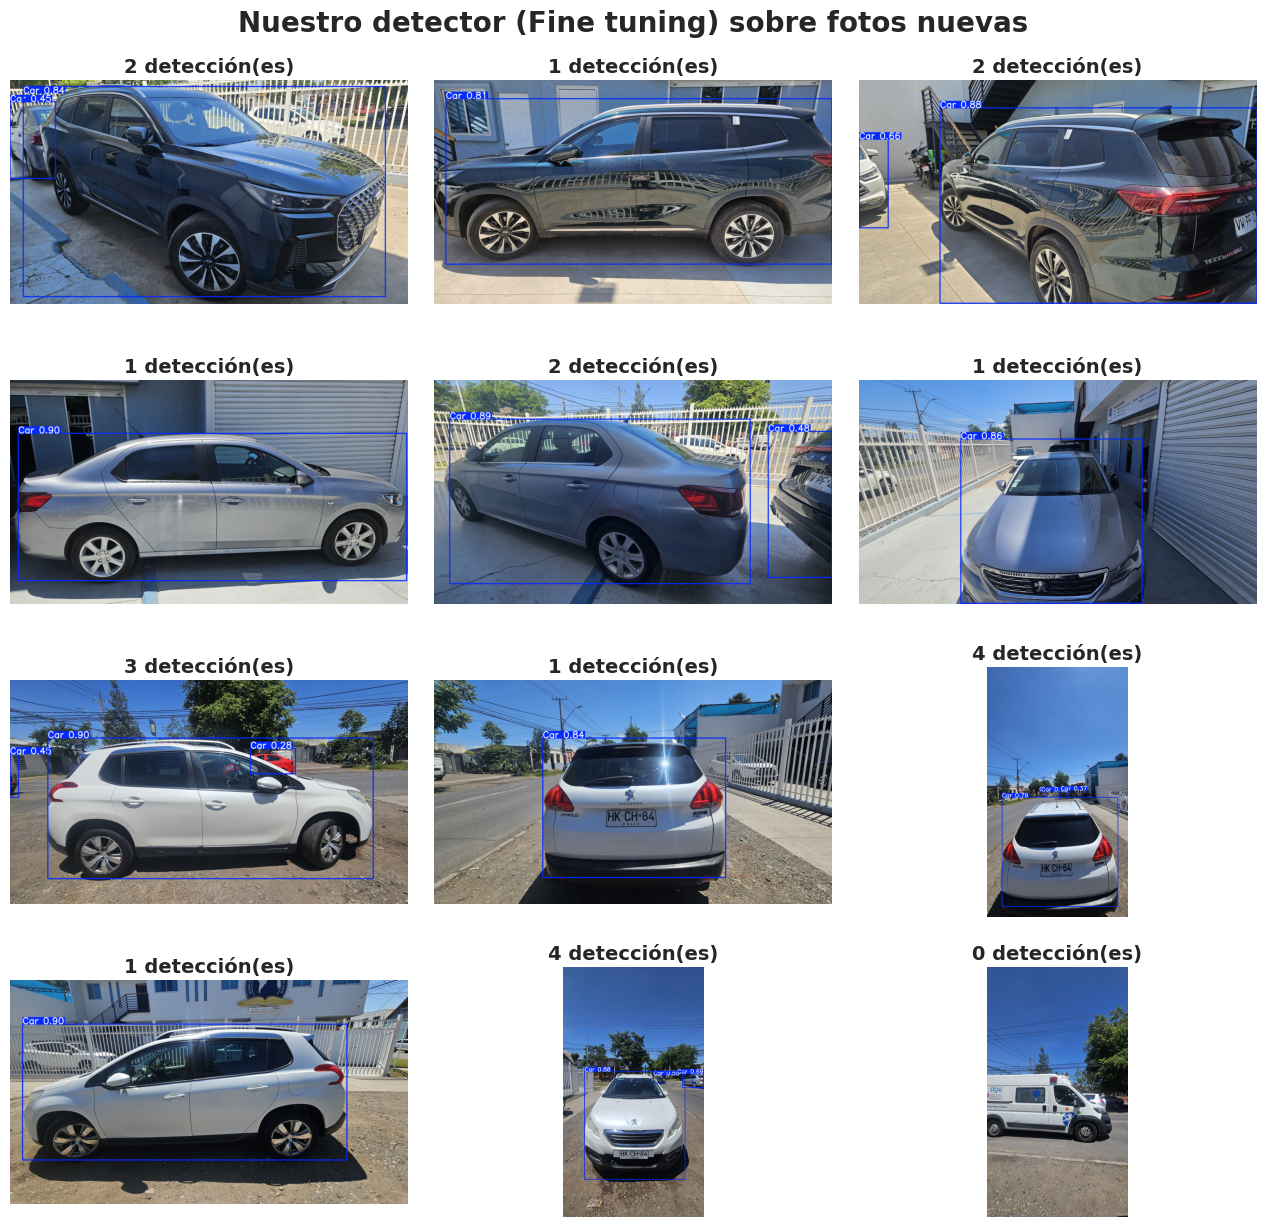

Gráfico guardado: f15_detector_en_fotos.png
Resultados guardados en: /content/resultados_c10/imagenes


,imagen,detecciones,clases
0,20261104_140739.jpg,2,Car
1,20261104_140752.jpg,1,Car
2,20261104_140807.jpg,2,Car
3,20261104_140818.jpg,1,Car
4,20261104_140830.jpg,2,Car
5,20261104_140840.jpg,1,Car
6,20261104_140930.jpg,3,Car
7,20261104_140937.jpg,1,Car
8,20261104_140942.jpg,4,Car
9,20261104_140949.jpg,1,Car


In [28]:
# ============================================================
# PARTE 9A · Imágenes
# ============================================================
tabla_imagenes = predecir_imagenes(RUTA_ELEGIDO, EJEMPLOS, RESULTADOS / "imagenes",
                                   f"Nuestro detector ({ELEGIDO}) sobre fotos nuevas",
                                   "f15_detector_en_fotos.png", max_mostrar=12)   # [Proyecto] hasta 12 de nuestras fotos
tabla_imagenes


Video 1: 20261104_141113.mp4
440 cuadros procesados (14.7 s de video). Velocidad media: 42.4 cuadros por segundo. Guardado en /content/resultados_c10/video_detectado_1.mp4


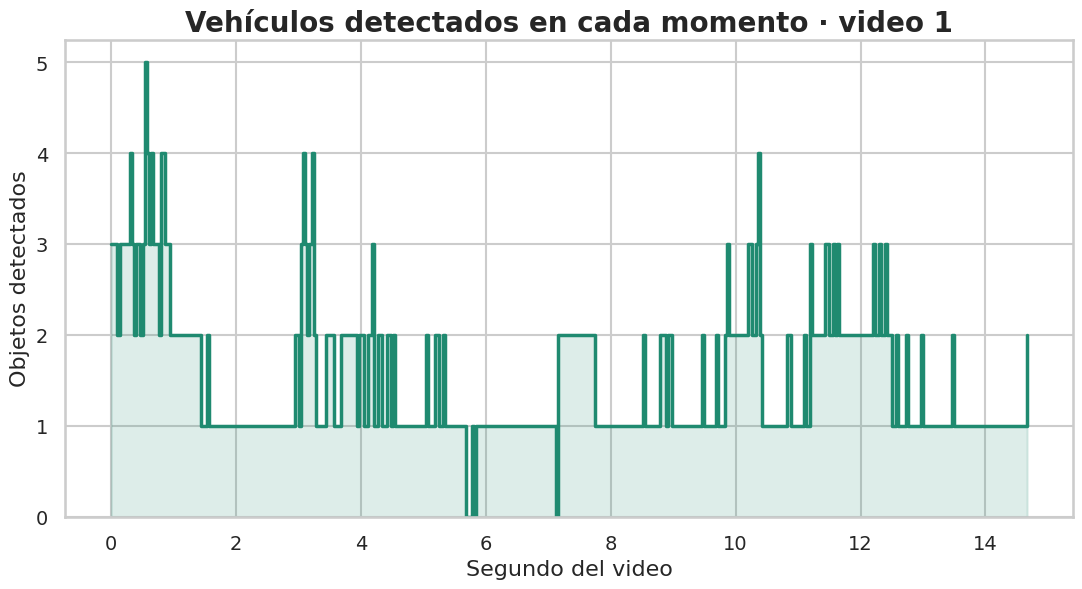

Gráfico guardado: f16_detecciones_por_cuadro_1.png


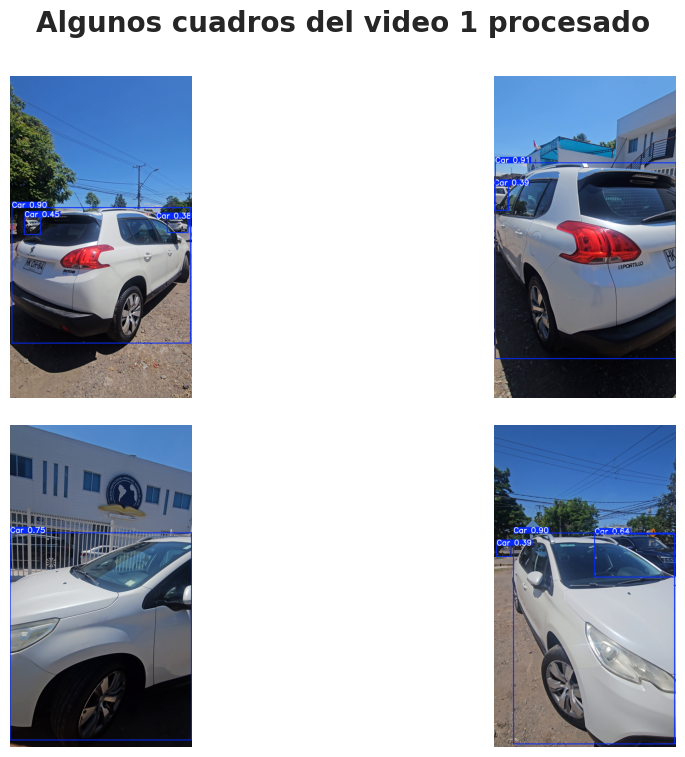

Gráfico guardado: f17_cuadros_video_1.png

Video 2: 20261104_141138.mp4
361 cuadros procesados (12.1 s de video). Velocidad media: 42.7 cuadros por segundo. Guardado en /content/resultados_c10/video_detectado_2.mp4


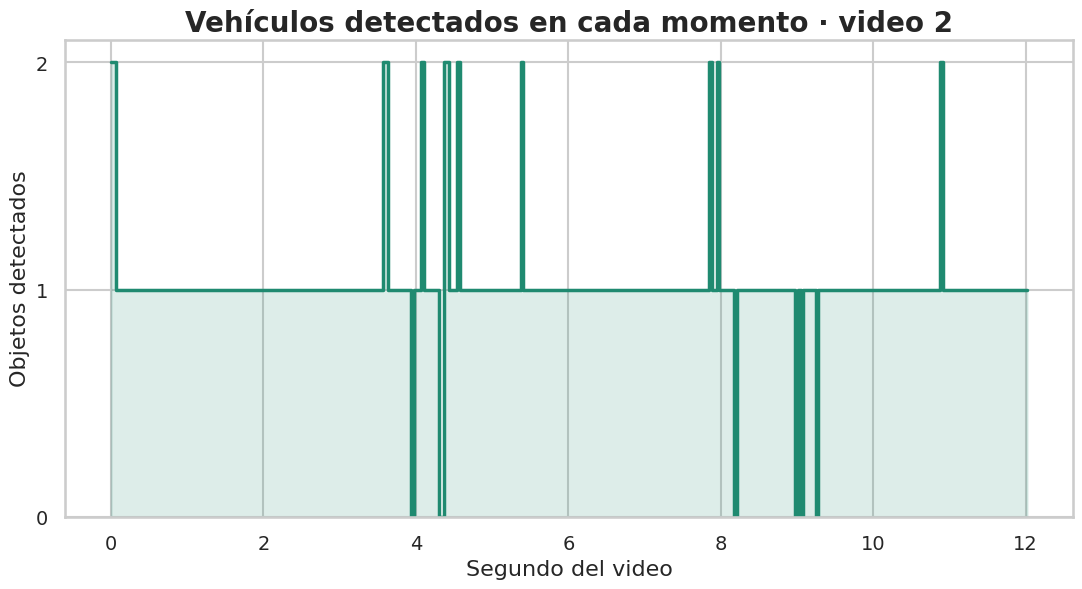

Gráfico guardado: f16_detecciones_por_cuadro_2.png


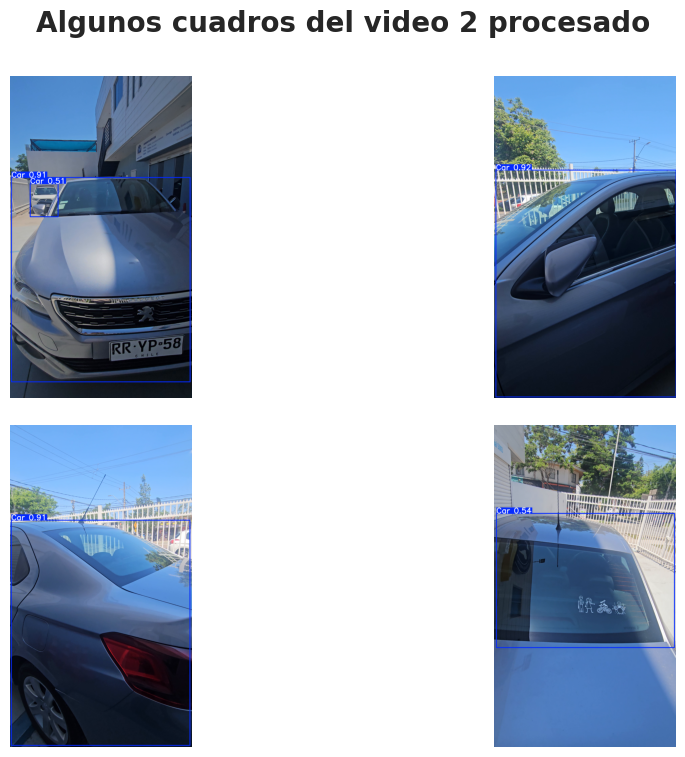

Gráfico guardado: f17_cuadros_video_2.png


In [29]:
# ============================================================
# PARTE 9B · Video
# ============================================================
# [Proyecto] Se procesan nuestros videos (los .mp4 de ejemplos/, máximo 2). Si no hay, se usa
# video_prueba.mp4 o, como último recurso, un video armado con fotos de Test (no sirve como prueba externa).
VIDEOS = sorted(CARPETA_EJEMPLOS.rglob("*.mp4"))[:2] if CARPETA_EJEMPLOS.exists() else []
if not VIDEOS and (BASE / "video_prueba.mp4").exists():
    VIDEOS = [BASE / "video_prueba.mp4"]
if not VIDEOS:
    print("No hay videos propios: se arma uno con 10 fotos de Test.")
    VIDEOS = [crear_video_desde_imagenes(listar_imagenes(DATOS / "images" / "test")[:10],
                                         RESULTADOS / "video_desde_fotos.mp4")]
NUMEROS["video"] = {}
for k, VIDEO in enumerate(VIDEOS, start=1):
    print(f"\nVideo {k}: {VIDEO.name}")
    tabla_video, cuadros = predecir_video(RUTA_ELEGIDO, VIDEO, RESULTADOS / f"video_detectado_{k}.mp4")
    graficar_detecciones_por_cuadro(tabla_video, f"Vehículos detectados en cada momento · video {k}",
                                    f"f16_detecciones_por_cuadro_{k}.png")
    galeria_cuadros(cuadros, f"Algunos cuadros del video {k} procesado", f"f17_cuadros_video_{k}.png")
    NUMEROS["video"][VIDEO.name] = {"cuadros": len(tabla_video), "segundos": float(tabla_video["segundo"].max()),
                                    "fps_procesamiento": float(1000 / tabla_video["ms"].mean()),
                                    "detecciones_promedio": float(tabla_video["detecciones"].mean())}


---
# Parte 10 · Guardar el modelo y los resultados

Todo lo importante queda en `resultados_c10/` y en un ZIP para descargar. **Descárgalo antes de cerrar Colab**: al cortarse la sesión se borra.

- `modelos/transfer_learning.pt`, `modelos/fine_tuning.pt` y `modelos/modelo_elegido.pt`: los pesos. Pesan unos pocos MB.
- `figuras/`: todos los gráficos.
- `numeros_c10.json`: las cifras (tiempos, épocas y métricas).
- `imagenes/` y `video_detectado.mp4`: los resultados de la Parte 9.

Para cargar el modelo después, en cualquier computador: `YOLO("modelo_elegido.pt")`.

**Para la Evaluación 04** se entrega `modelos/modelo_elegido.pt` y los dos videos.

In [30]:
# ============================================================
# PARTE 10A · Modelos, cifras y ZIP
# ============================================================
MODELOS = RESULTADOS / "modelos"
MODELOS.mkdir(exist_ok=True)
shutil.copy2(RUTA_TL, MODELOS / "transfer_learning.pt")
shutil.copy2(RUTA_FT, MODELOS / "fine_tuning.pt")
shutil.copy2(RUTA_ELEGIDO, MODELOS / "modelo_elegido.pt")
for run in (RUN_TL, RUN_FT):
    shutil.copy2(run / "results.csv", RESULTADOS / f"results_{run.name}.csv")
NUMEROS["mb_modelo"] = (MODELOS / "modelo_elegido.pt").stat().st_size / 1e6

with open(RESULTADOS / "numeros_c10.json", "w", encoding="utf-8") as f:
    json.dump(NUMEROS, f, ensure_ascii=False, indent=2, default=str)

ZIP = BASE / "resultados_c10.zip"
with zipfile.ZipFile(ZIP, "w", zipfile.ZIP_DEFLATED) as z:
    for archivo in RESULTADOS.rglob("*"):
        if archivo.is_file():
            z.write(archivo, archivo.relative_to(BASE))
print(f"ZIP listo: {ZIP} ({ZIP.stat().st_size / 1e6:.1f} MB)")
print(f"El modelo elegido pesa {NUMEROS['mb_modelo']:.1f} MB")

ZIP listo: /content/resultados_c10.zip (283.2 MB)
El modelo elegido pesa 5.4 MB


In [31]:
# ============================================================
# PARTE 10B · Descargar (solo en Colab)
# ============================================================
if Path("/content").exists():
    from google.colab import files
    files.download(str(ZIP))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# Cierre · Qué observamos

**1. Entrenamiento:** Se realizaron dos etapas de entrenamiento: Transfer Learning y Fine Tuning. Ambos modelos lograron aprender a detectar vehículos. El entrenamiento se realizó utilizando una GPU Tesla T4 y las curvas permiten observar la evolución del aprendizaje y las diferencias entre entrenamiento y validación.

**2. Elección:** Se seleccionó el modelo Fine Tuning porque obtuvo el mejor resultado en mAP50-95 durante la validación, alcanzando 0.500 frente a 0.497 del Transfer Learning. Aunque la diferencia fue pequeña, Fine Tuning presentó un mejor resultado en esta métrica.

**3. Test:** El modelo elegido obtuvo una precisión de 0.815, Recall de 0.656, mAP50 de 0.737 y mAP50-95 de 0.538. Estos resultados fueron ligeramente superiores a los obtenidos durante la validación. Sin embargo, hay que considerar que el conjunto de Test contiene solamente 63 imágenes, por lo que cada error puede influir considerablemente en los resultados.

**4. Errores:** Durante la evaluación se identificaron 35 objetos perdidos, 6 falsas detecciones, 2 clases confundidas y 8 cajas mal ubicadas. El principal problema fue la pérdida de objetos, lo que demuestra que todavía existen vehículos que el modelo no logra detectar correctamente.

**5. Fuera del dataset:** En las fotografías y videos grabados por el grupo, el modelo logró detectar vehículos y procesar ambos videos a una velocidad aproximada de 42 cuadros por segundo. Sin embargo, algunas fotografías no tuvieron detecciones, lo que demuestra que todavía presenta dificultades en determinadas condiciones reales.

**6. Límites:** El proyecto presenta algunas limitaciones: el tamaño reducido del dataset, el desequilibrio entre las clases, el redimensionamiento de las imágenes a 416×416 y la cantidad limitada de vehículos anotados. Por lo tanto, sería necesario utilizar más imágenes y mejorar la variedad de los datos para conseguir un detector más preciso y confiable.

**Conclusión general:** El proyecto permitió desarrollar y evaluar un detector de vehículos utilizando YOLO26n. Se comprobó que Fine Tuning obtuvo el mejor resultado en validación y que el modelo es capaz de realizar detecciones en imágenes y videos reales. No obstante, todavía existen errores de detección que podrían reducirse mediante un dataset más amplio y un entrenamiento mejorado.